In [1]:
import pandas
train = pandas.read_csv('train.csv')
test = pandas.read_csv('test.csv')


In [2]:
print(train.shape)
print(train.info())
print(train.isnull().sum())
print(train.duplicated().sum())
print(train.head())

(511, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 511 entries, 0 to 510
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   PhraseId    511 non-null    int64 
 1   SentenceId  511 non-null    int64 
 2   Phrase      511 non-null    object
 3   Sentiment   511 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 16.1+ KB
None
PhraseId      0
SentenceId    0
Phrase        0
Sentiment     0
dtype: int64
0
   PhraseId  SentenceId                                             Phrase  \
0    144934        7871  An unremittingly ugly movie to look at , liste...   
1    137519        7440           Makes 98 minutes feel like three hours .   
2     70201        3575  -LRB- N -RRB- o matter how much good will the ...   
3     19954         885  An erotic thriller that 's neither too erotic ...   
4    101128        5315  Bray is completely at sea ; with nothing but a...   

   Sentiment  
0          0  
1          0 

The data is clear, there is no  null value or duplicated data

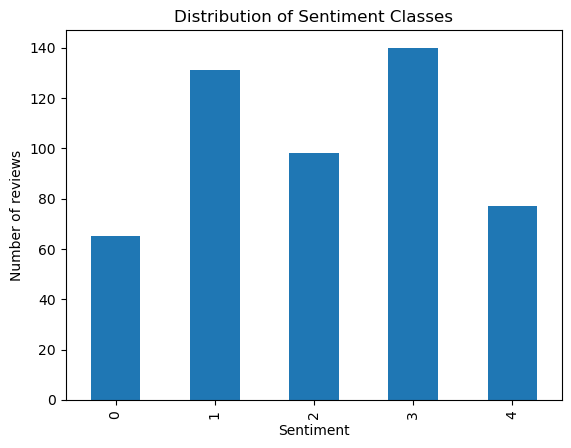

In [3]:
import matplotlib.pyplot as plt

train["Sentiment"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.title("Distribution of Sentiment Classes")
plt.show()

The training dataset is imbalanced, we might need data augmentation or assign different weights to each class. Otherwise, the model will be biased toward predicting the majority classes, Real-world performance would be poor

Compute weights for each class after Stratified split


We will also need a function for computing metrics of interest in the validation set. In this case, we will plot both the loss and the F1-score in the validation set. The F1-score of a classifier is the [harmonic mean](https://en.wikipedia.org/wiki/Harmonic_mean) of its [precision and recall](https://en.wikipedia.org/wiki/Precision_and_recall), two metrics that are more useful than accuracy for imbalanced datasets. [This blog post](https://towardsdatascience.com/accuracy-precision-recall-or-f1-331fb37c5cb9) can help you to familiarize yourself with these new metrics.

For evaluation metrics we are using Macro F1.

Stratified split, keeping roughly the same class proportions in both the training and validation sets.

In [ ]:
import pandas
train = pandas.read_csv('train.csv')
test = pandas.read_csv('test.csv')
#Stratified split
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train,
    test_size=0.2,
    random_state=42,
    stratify=train["Sentiment"]
)

cross-validation after the baseline?

In [5]:
# Compute weights for each class
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1, 2, 3, 4])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["Sentiment"]
)

print(weights)

[1.56923077 0.77714286 1.04615385 0.72857143 1.33770492]


In [6]:
X_train = train_df["Phrase"]
y_train = train_df["Sentiment"]

X_val = val_df["Phrase"]
y_val = val_df["Sentiment"]

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(train_df["Phrase"])
X_val_tfidf = tfidf.transform(val_df["Phrase"])

In [8]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1, 2, 3, 4])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{0: 1.5692307692307692, 1: 0.7771428571428571, 2: 1.0461538461538462, 3: 0.7285714285714285, 4: 1.337704918032787}


In [9]:
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(
    max_iter=2000
)

baseline_model.fit(
    X_train_tfidf,
    y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [10]:
baseline_pred = baseline_model.predict(X_val_tfidf)

In [11]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

print("Accuracy:",
      accuracy_score(y_val, baseline_pred))

print("Macro F1:",
      f1_score(y_val, baseline_pred, average="macro"))

print(
    classification_report(
        y_val,
        baseline_pred,
        digits=3
    )
)

Accuracy: 0.3106796116504854
Macro F1: 0.18362283852479933
              precision    recall  f1-score   support

           0      0.000     0.000     0.000        13
           1      0.312     0.577     0.405        26
           2      0.000     0.000     0.000        20
           3      0.302     0.571     0.395        28
           4      1.000     0.062     0.118        16

    accuracy                          0.311       103
   macro avg      0.323     0.242     0.184       103
weighted avg      0.316     0.311     0.228       103



/opt/anaconda3/envs/dml/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/envs/dml/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/envs/dml/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0]

Now weight version

In [12]:
weighted_model = LogisticRegression(
    class_weight=class_weights,
    max_iter=2000
)

weighted_model.fit(
    X_train_tfidf,
    y_train
)

weighted_pred = weighted_model.predict(
    X_val_tfidf
)

In [13]:
print("Accuracy:",
      accuracy_score(y_val, weighted_pred))

print("Macro F1:",
      f1_score(y_val, weighted_pred, average="macro"))

print(
    classification_report(
        y_val,
        weighted_pred,
        digits=3
    )
)

Accuracy: 0.2524271844660194
Macro F1: 0.23402440536280394
              precision    recall  f1-score   support

           0      0.214     0.231     0.222        13
           1      0.303     0.385     0.339        26
           2      0.125     0.100     0.111        20
           3      0.296     0.286     0.291        28
           4      0.231     0.188     0.207        16

    accuracy                          0.252       103
   macro avg      0.234     0.238     0.234       103
weighted avg      0.244     0.252     0.246       103



Linear SVM

In [14]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

svm = LinearSVC(C=1.0)

svm.fit(X_train_tfidf, train_df["Sentiment"])

pred = svm.predict(X_val_tfidf)

print("Accuracy:", accuracy_score(val_df["Sentiment"], pred))
print(
    "Macro F1:",
    f1_score(
        val_df["Sentiment"],
        pred,
        average="macro"
    )
)

print(
    classification_report(
        val_df["Sentiment"],
        pred,
        digits=3
    )
)

Accuracy: 0.2524271844660194
Macro F1: 0.21598901098901097
              precision    recall  f1-score   support

           0      0.143     0.077     0.100        13
           1      0.282     0.423     0.338        26
           2      0.167     0.100     0.125        20
           3      0.257     0.321     0.286        28
           4      0.300     0.188     0.231        16

    accuracy                          0.252       103
   macro avg      0.230     0.222     0.216       103
weighted avg      0.238     0.252     0.236       103



In [15]:
svm_weighted = LinearSVC(
    C=1.0,
    class_weight="balanced"
)

svm_weighted.fit(X_train_tfidf, train_df["Sentiment"])

pred = svm_weighted.predict(X_val_tfidf)

print("Accuracy:", accuracy_score(val_df["Sentiment"], pred))
print(
    "Macro F1:",
    f1_score(
        val_df["Sentiment"],
        pred,
        average="macro"
    )
)

print(
    classification_report(
        val_df["Sentiment"],
        pred,
        digits=3
    )
)

Accuracy: 0.22330097087378642
Macro F1: 0.19835753570411666
              precision    recall  f1-score   support

           0      0.077     0.077     0.077        13
           1      0.281     0.346     0.310        26
           2      0.125     0.100     0.111        20
           3      0.258     0.286     0.271        28
           4      0.273     0.188     0.222        16

    accuracy                          0.223       103
   macro avg      0.203     0.199     0.198       103
weighted avg      0.217     0.223     0.218       103



In [16]:
from sklearn.naive_bayes import ComplementNB

nb = ComplementNB()

nb.fit(
    X_train_tfidf,
    train_df["Sentiment"]
)

pred = nb.predict(X_val_tfidf)
print("Accuracy:", accuracy_score(val_df["Sentiment"], pred))
print(
    "Macro F1:",
    f1_score(
        val_df["Sentiment"],
        pred,
        average="macro"
    )
)

print(
    classification_report(
        val_df["Sentiment"],
        pred,
        digits=3
    )
)

Accuracy: 0.2912621359223301
Macro F1: 0.24924403499240086
              precision    recall  f1-score   support

           0      0.333     0.154     0.211        13
           1      0.340     0.615     0.438        26
           2      0.077     0.050     0.061        20
           3      0.267     0.286     0.276        28
           4      0.429     0.188     0.261        16

    accuracy                          0.291       103
   macro avg      0.289     0.258     0.249       103
weighted avg      0.282     0.291     0.265       103



In [17]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=5,
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    random_state=42
)

xgb.fit(
    X_train_tfidf,
    y_train
)

pred = xgb.predict(X_val_tfidf)
print("Accuracy:", accuracy_score(val_df["Sentiment"], pred))
print(
    "Macro F1:",
    f1_score(
        val_df["Sentiment"],
        pred,
        average="macro"
    )
)

print(
    classification_report(
        val_df["Sentiment"],
        pred,
        digits=3
    )
)

Accuracy: 0.22330097087378642
Macro F1: 0.19039748735315024
              precision    recall  f1-score   support

           0      0.143     0.077     0.100        13
           1      0.171     0.269     0.209        26
           2      0.286     0.200     0.235        20
           3      0.278     0.357     0.312        28
           4      0.200     0.062     0.095        16

    accuracy                          0.223       103
   macro avg      0.215     0.193     0.190       103
weighted avg      0.223     0.223     0.211       103



In [18]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

X_train_svd = svd.fit_transform(X_train_tfidf)
X_val_svd = svd.transform(X_val_tfidf)
xgb.fit(
    X_train_svd,
    y_train
)

pred = xgb.predict(X_val_svd)
print("Accuracy:", accuracy_score(val_df["Sentiment"], pred))
print(
    "Macro F1:",
    f1_score(
        val_df["Sentiment"],
        pred,
        average="macro"
    )
)

print(
    classification_report(
        val_df["Sentiment"],
        pred,
        digits=3
    )
)

Accuracy: 0.30097087378640774
Macro F1: 0.2423834988540871
              precision    recall  f1-score   support

           0      0.143     0.077     0.100        13
           1      0.375     0.231     0.286        26
           2      0.286     0.200     0.235        20
           3      0.300     0.643     0.409        28
           4      0.333     0.125     0.182        16

    accuracy                          0.301       103
   macro avg      0.287     0.255     0.242       103
weighted avg      0.302     0.301     0.270       103



bert

In [19]:
pip install transformers torch scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [25]:
import sys
import importlib.metadata as md

print("Python:", sys.executable)
print("Torch:", md.version("torch"))
print("Transformers:", md.version("transformers"))
print("NumPy:", md.version("numpy"))

Python: /opt/anaconda3/envs/dml/bin/python
Torch: 2.1.0
Transformers: 4.56.0
NumPy: 1.26.4


In [26]:
%pip install --upgrade --force-reinstall \
    "numpy==1.26.4" \
    "torch>=2.2" \
    "transformers==4.56.1"

  Using cached numpy-1.26.4-cp311-cp311-macosx_11_0_arm64.whl.metadata (114 kB)
  Using cached huggingface_hub-0.36.2-py3-none-any.whl.metadata (15 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached pyyaml-6.0.3-cp311-cp311-macosx_11_0_arm64.whl.metadata (2.4 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached tokenizers-0.22.2-cp39-abi3-macosx_11_0_arm64.whl.metadata (7.3 kB)
  Using cached safetensors-0.8.0-cp310-abi3-macosx_11_0_arm64.whl.metadata (4.2 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using c

In [1]:
import numpy as np
import torch
import transformers

print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

NumPy: 1.26.4
PyTorch: 2.14.1
Transformers: 4.56.1


In [2]:
import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [3]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(device)

mps


In [4]:
MODEL_NAME = "google-bert/bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5
)

model = model.to(device)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

/opt/anaconda3/envs/dml/lib/python3.11/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'Could not load this library: /opt/anaconda3/envs/dml/lib/python3.11/site-packages/torchvision/image.so'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [5]:
class MovieReviewDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length=64):
        self.texts = dataframe["Phrase"].astype(str).tolist()
        self.labels = dataframe["Sentiment"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }

In [8]:
import pandas
train = pandas.read_csv('train.csv')
test = pandas.read_csv('test.csv')

In [9]:
#Stratified split
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train,
    test_size=0.2,
    random_state=42,
    stratify=train["Sentiment"]
)

In [10]:
train_dataset = MovieReviewDataset(
    train_df,
    tokenizer
)

val_dataset = MovieReviewDataset(
    val_df,
    tokenizer
)

In [11]:
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False
)

In [12]:
optimizer = AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

In [13]:
def train_one_epoch(model, dataloader, optimizer, device):

    model.train()

    total_loss = 0

    for batch in dataloader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)

In [14]:
def evaluate(model, dataloader, device):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for batch in dataloader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = outputs.logits

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return (
        accuracy,
        macro_f1,
        all_labels,
        all_predictions
    )

In [15]:
EPOCHS = 5

best_f1 = 0
best_model_state = None

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        device
    )

    accuracy, macro_f1, _, _ = evaluate(
        model,
        val_loader,
        device
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if macro_f1 > best_f1:
        best_f1 = macro_f1

        best_model_state = {
            key: value.cpu().clone()
            for key, value in model.state_dict().items()
        }

Epoch 1/5 | Loss: 1.6031 | Accuracy: 0.3010 | Macro F1: 0.1407
Epoch 2/5 | Loss: 1.4161 | Accuracy: 0.4369 | Macro F1: 0.2661
Epoch 3/5 | Loss: 0.9989 | Accuracy: 0.4854 | Macro F1: 0.4075
Epoch 4/5 | Loss: 0.6254 | Accuracy: 0.4854 | Macro F1: 0.3852
Epoch 5/5 | Loss: 0.3630 | Accuracy: 0.4951 | Macro F1: 0.4083


In [16]:
model.load_state_dict(best_model_state)

model = model.to(device)

In [17]:
accuracy, macro_f1, y_true, y_pred = evaluate(
    model,
    val_loader,
    device
)

print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)

print(
    classification_report(
        y_true,
        y_pred,
        digits=3
    )
)

Accuracy: 0.49514563106796117
Macro F1: 0.40829814429814426
              precision    recall  f1-score   support

           0      0.000     0.000     0.000        13
           1      0.396     0.731     0.514        26
           2      0.800     0.200     0.320        20
           3      0.541     0.714     0.615        28
           4      0.727     0.500     0.593        16

    accuracy                          0.495       103
   macro avg      0.493     0.429     0.408       103
weighted avg      0.515     0.495     0.451       103



weighted cross-entropy loss

In [29]:
class_weights = {
    0: 1.569,
    1: 0.777,
    2: 1.046,
    3: 0.729,
    4: 1.338
}

In [30]:
import torch
import torch.nn as nn

weights = torch.tensor(
    [
        class_weights[0],
        class_weights[1],
        class_weights[2],
        class_weights[3],
        class_weights[4]
    ],
    dtype=torch.float
).to(device)

criterion = nn.CrossEntropyLoss(weight=weights)

In [20]:
def train_one_epoch_weighted(
    model,
    dataloader,
    optimizer,
    device,
    criterion
):
    model.train()

    total_loss = 0

    for batch in dataloader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(
            outputs.logits,
            labels
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)

In [27]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5
).to(device)

# Freeze embeddings
for param in model.bert.embeddings.parameters():
    param.requires_grad = False

# Freeze first 8 encoder layers
for layer in model.bert.encoder.layer[:8]:
    for param in layer.parameters():
        param.requires_grad = False


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [28]:
optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=2e-5,
    weight_decay=0.01
)

In [37]:
from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW

# Recreate BERT using eager attention instead of SDPA
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5,
    attn_implementation="eager"
).to(device)

# Freeze embedding layer
for param in model.bert.embeddings.parameters():
    param.requires_grad = False

# Freeze first 8 BERT encoder layers
for layer in model.bert.encoder.layer[:8]:
    for param in layer.parameters():
        param.requires_grad = False

# Optimizer only sees trainable parameters
optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=2e-5,
    weight_decay=0.01
)

print("Device:", device)
print("Attention implementation:", model.config._attn_implementation)

trainable = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel() for p in model.parameters()
)

print(f"Trainable parameters: {trainable:,}")
print(f"Total parameters: {total:,}")
print(f"Trainable: {100 * trainable / total:.2f}%")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Device: mps
Attention implementation: eager
Trainable parameters: 28,945,925
Total parameters: 109,486,085
Trainable: 26.44%


Epoch 1/5 | Train Loss: 1.5830 | Train Acc: 0.2819 | Train F1: 0.1453 | Val Loss: 1.5472 | Val Acc: 0.3786 | Val F1: 0.1961
Epoch 2/5 | Train Loss: 1.4919 | Train Acc: 0.3627 | Train F1: 0.2188 | Val Loss: 1.3966 | Val Acc: 0.4563 | Val F1: 0.2866
Epoch 3/5 | Train Loss: 1.2490 | Train Acc: 0.5098 | Train F1: 0.3803 | Val Loss: 1.2500 | Val Acc: 0.4466 | Val F1: 0.3511
Epoch 4/5 | Train Loss: 1.0580 | Train Acc: 0.5564 | Train F1: 0.4603 | Val Loss: 1.2187 | Val Acc: 0.4369 | Val F1: 0.3689
Epoch 5/5 | Train Loss: 0.8825 | Train Acc: 0.6642 | Train F1: 0.5997 | Val Loss: 1.1704 | Val Acc: 0.4757 | Val F1: 0.4505

BEST MODEL RESULTS
Best Epoch: 5
Validation Loss: 1.1704
Validation Accuracy: 0.4757
Validation Macro F1: 0.4505

Classification Report:
              precision    recall  f1-score   support

           0      0.250     0.231     0.240        13
           1      0.429     0.462     0.444        26
           2      0.353     0.300     0.324        20
           3      0.576  

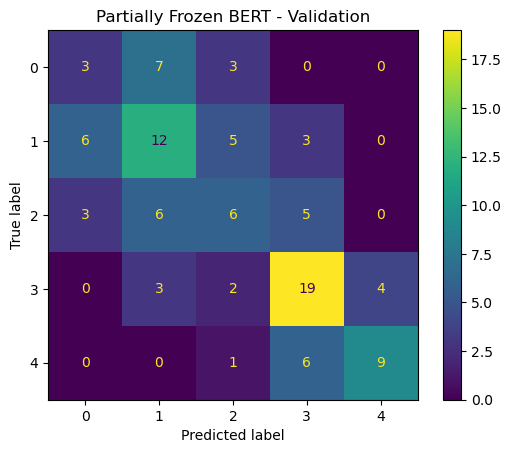

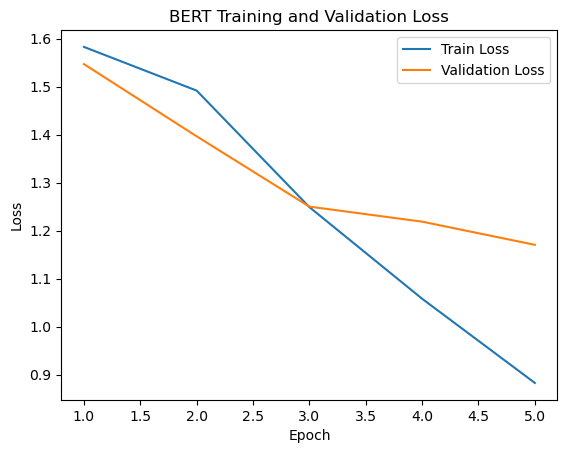

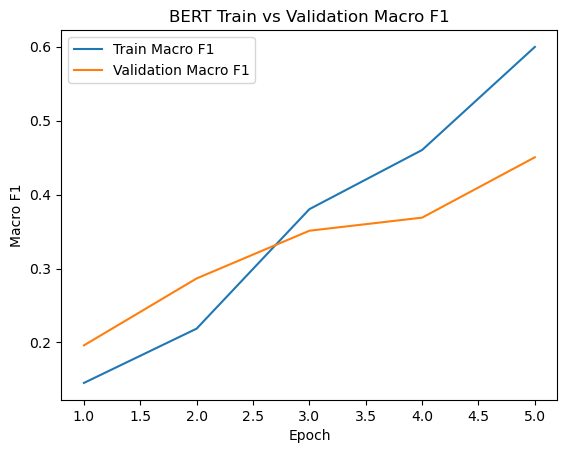

In [38]:
import copy
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# =========================
# SETTINGS
# =========================
EPOCHS = 5


# =========================
# TRAIN ONE EPOCH
# =========================
def train_one_epoch(model, dataloader, optimizer, device):
    model.train()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for batch in dataloader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        logits = outputs.logits

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(logits, dim=1)

        all_labels.extend(labels.detach().cpu().numpy())
        all_predictions.extend(predictions.detach().cpu().numpy())

    avg_loss = total_loss / len(dataloader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1


# =========================
# EVALUATION
# =========================
def evaluate(model, dataloader, device):
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            logits = outputs.logits

            total_loss += loss.item()

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    avg_loss = total_loss / len(dataloader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        all_labels,
        all_predictions
    )


# =========================
# TRAINING LOOP
# =========================
best_macro_f1 = -1
best_model_state = None
best_epoch = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_macro_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

for epoch in range(EPOCHS):

    (
        train_loss,
        train_accuracy,
        train_macro_f1
    ) = train_one_epoch(
        model,
        train_loader,
        optimizer,
        device
    )

    (
        val_loss,
        val_accuracy,
        val_macro_f1,
        _,
        _
    ) = evaluate(
        model,
        val_loader,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["train_macro_f1"].append(train_macro_f1)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_macro_f1)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Train F1: {train_macro_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_macro_f1:.4f}"
    )

    # Save best model according to validation Macro F1
    if val_macro_f1 > best_macro_f1:
        best_macro_f1 = val_macro_f1
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(
            model.state_dict()
        )


# =========================
# RESTORE BEST MODEL
# =========================
model.load_state_dict(best_model_state)
model.to(device)


# =========================
# FINAL VALIDATION RESULTS
# =========================
(
    val_loss,
    val_accuracy,
    val_macro_f1,
    y_true,
    y_pred
) = evaluate(
    model,
    val_loader,
    device
)

print("\n" + "=" * 50)
print("BEST MODEL RESULTS")
print("=" * 50)

print(f"Best Epoch: {best_epoch}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Macro F1: {val_macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        digits=3,
        zero_division=0
    )
)


# =========================
# FINAL TRAIN PERFORMANCE
# =========================
(
    train_loss_final,
    train_accuracy_final,
    train_macro_f1_final,
    _,
    _
) = evaluate(
    model,
    train_loader,
    device
)

print("\n" + "=" * 50)
print("OVERFITTING CHECK")
print("=" * 50)

print(f"Train Accuracy:      {train_accuracy_final:.4f}")
print(f"Train Macro F1:      {train_macro_f1_final:.4f}")

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Macro F1: {val_macro_f1:.4f}")


# =========================
# CONFUSION MATRIX
# =========================
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred
)

plt.title("Partially Frozen BERT - Validation")
plt.show()


# =========================
# TRAINING CURVES
# =========================
plt.figure()
plt.plot(
    range(1, EPOCHS + 1),
    history["train_loss"],
    label="Train Loss"
)
plt.plot(
    range(1, EPOCHS + 1),
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BERT Training and Validation Loss")
plt.legend()
plt.show()


plt.figure()
plt.plot(
    range(1, EPOCHS + 1),
    history["train_macro_f1"],
    label="Train Macro F1"
)
plt.plot(
    range(1, EPOCHS + 1),
    history["val_macro_f1"],
    label="Validation Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("BERT Train vs Validation Macro F1")
plt.legend()
plt.show()

Try training only the last 2 layers:

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Device: mps
Trainable parameters: 14,770,181
Total parameters: 109,486,085
Trainable: 13.49%
Epoch 1/8 | Train Loss: 1.5990 | Train Acc: 0.2328 | Train F1: 0.1514 | Val Loss: 1.5331 | Val Acc: 0.3786 | Val F1: 0.2018
Epoch 2/8 | Train Loss: 1.5086 | Train Acc: 0.3824 | Train F1: 0.2495 | Val Loss: 1.4957 | Val Acc: 0.3689 | Val F1: 0.2250
Epoch 3/8 | Train Loss: 1.4259 | Train Acc: 0.3824 | Train F1: 0.2889 | Val Loss: 1.3964 | Val Acc: 0.4272 | Val F1: 0.3418
Epoch 4/8 | Train Loss: 1.2776 | Train Acc: 0.4926 | Train F1: 0.4262 | Val Loss: 1.3221 | Val Acc: 0.4175 | Val F1: 0.3644
Epoch 5/8 | Train Loss: 1.1440 | Train Acc: 0.5784 | Train F1: 0.5444 | Val Loss: 1.2332 | Val Acc: 0.4660 | Val F1: 0.4008
Epoch 6/8 | Train Loss: 1.0172 | Train Acc: 0.6078 | Train F1: 0.5820 | Val Loss: 1.2545 | Val Acc: 0.3786 | Val F1: 0.3499
Epoch 7/8 | Train Loss: 0.8931 | Train Acc: 0.6838 | Train F1: 0.6733 | Val Loss: 1.2252 | Val Acc: 0.4854 | Val F1: 0.4320
Epoch 8/8 | Train Loss: 0.7890 | Train 

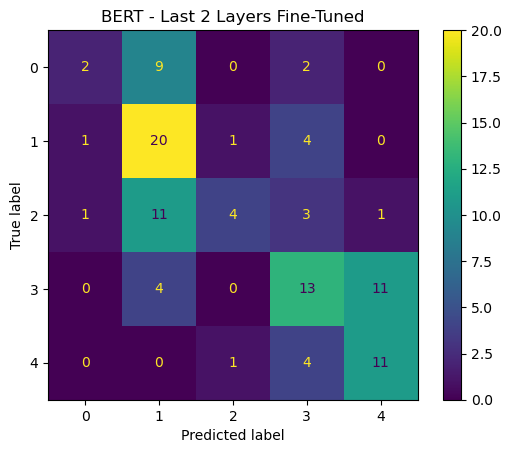

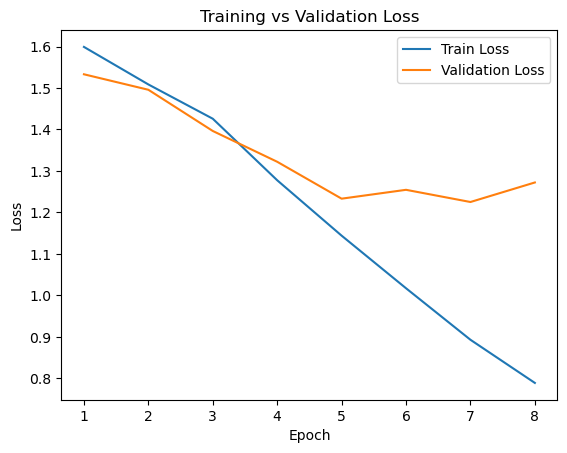

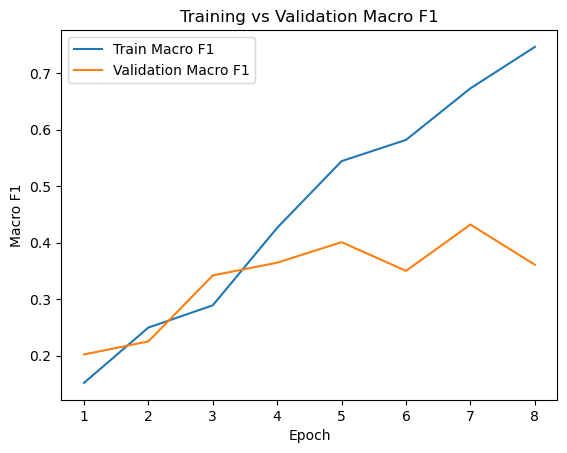

In [39]:
import copy
import torch
import matplotlib.pyplot as plt

from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# =========================
# SETTINGS
# =========================
EPOCHS = 8
MODEL_NAME = "google-bert/bert-base-uncased"

# =========================
# LOAD FRESH BERT
# =========================
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5,
    attn_implementation="eager"
).to(device)

# =========================
# FREEZE EMBEDDINGS
# =========================
for param in model.bert.embeddings.parameters():
    param.requires_grad = False

# =========================
# FREEZE FIRST 10 / 12 LAYERS
# Only layers 10 and 11 remain trainable
# =========================
for layer in model.bert.encoder.layer[:10]:
    for param in layer.parameters():
        param.requires_grad = False

# =========================
# OPTIMIZER
# =========================
optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=2e-5,
    weight_decay=0.01
)

# =========================
# PARAMETER CHECK
# =========================
trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel()
    for p in model.parameters()
)

print(f"Device: {device}")
print(f"Trainable parameters: {trainable:,}")
print(f"Total parameters: {total:,}")
print(f"Trainable: {100 * trainable / total:.2f}%")

# =========================
# TRAIN FUNCTION
# =========================
def train_one_epoch(model, dataloader, optimizer, device):
    model.train()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for batch in dataloader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        logits = outputs.logits

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(logits, dim=1)

        all_labels.extend(labels.detach().cpu().numpy())
        all_predictions.extend(predictions.detach().cpu().numpy())

    avg_loss = total_loss / len(dataloader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1

# =========================
# EVALUATION FUNCTION
# =========================
def evaluate(model, dataloader, device):
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_loss += outputs.loss.item()

            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    avg_loss = total_loss / len(dataloader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        all_labels,
        all_predictions
    )

# =========================
# TRAINING LOOP
# =========================
best_macro_f1 = -1
best_model_state = None
best_epoch = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_macro_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

for epoch in range(EPOCHS):

    (
        train_loss,
        train_accuracy,
        train_macro_f1
    ) = train_one_epoch(
        model,
        train_loader,
        optimizer,
        device
    )

    (
        val_loss,
        val_accuracy,
        val_macro_f1,
        _,
        _
    ) = evaluate(
        model,
        val_loader,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["train_macro_f1"].append(train_macro_f1)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_macro_f1)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Train F1: {train_macro_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_macro_f1:.4f}"
    )

    if val_macro_f1 > best_macro_f1:
        best_macro_f1 = val_macro_f1
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(
            model.state_dict()
        )

# =========================
# RESTORE BEST MODEL
# =========================
model.load_state_dict(best_model_state)
model.to(device)

# =========================
# FINAL VALIDATION
# =========================
(
    val_loss,
    val_accuracy,
    val_macro_f1,
    y_true,
    y_pred
) = evaluate(
    model,
    val_loader,
    device
)

print("\n" + "=" * 50)
print("BEST MODEL RESULTS")
print("=" * 50)

print(f"Best Epoch: {best_epoch}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Macro F1: {val_macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        digits=3,
        zero_division=0
    )
)

# =========================
# TRAIN PERFORMANCE
# =========================
(
    train_loss_final,
    train_accuracy_final,
    train_macro_f1_final,
    _,
    _
) = evaluate(
    model,
    train_loader,
    device
)

print("\n" + "=" * 50)
print("OVERFITTING CHECK")
print("=" * 50)

print(f"Train Accuracy:      {train_accuracy_final:.4f}")
print(f"Train Macro F1:      {train_macro_f1_final:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Macro F1: {val_macro_f1:.4f}")

# =========================
# CONFUSION MATRIX
# =========================
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred
)

plt.title("BERT - Last 2 Layers Fine-Tuned")
plt.show()

# =========================
# LOSS CURVE
# =========================
plt.figure()

plt.plot(
    range(1, EPOCHS + 1),
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

# =========================
# MACRO F1 CURVE
# =========================
plt.figure()

plt.plot(
    range(1, EPOCHS + 1),
    history["train_macro_f1"],
    label="Train Macro F1"
)

plt.plot(
    range(1, EPOCHS + 1),
    history["val_macro_f1"],
    label="Validation Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("Training vs Validation Macro F1")
plt.legend()
plt.show()

Train less didn't improve

Class weights:
Class 0: 1.5692
Class 1: 0.7771
Class 2: 1.0462
Class 3: 0.7286
Class 4: 1.3377


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Device: mps
Trainable parameters: 28,945,925
Total parameters: 109,486,085
Trainable: 26.44%
Epoch 1/8 | Train Loss: 1.6319 | Train Acc: 0.1765 | Train F1: 0.1458 | Val Loss: 1.5653 | Val Acc: 0.2621 | Val F1: 0.1925
Epoch 2/8 | Train Loss: 1.4800 | Train Acc: 0.3578 | Train F1: 0.3106 | Val Loss: 1.4212 | Val Acc: 0.3495 | Val F1: 0.2661
Epoch 3/8 | Train Loss: 1.2623 | Train Acc: 0.4632 | Train F1: 0.4380 | Val Loss: 1.2541 | Val Acc: 0.4369 | Val F1: 0.3491
Epoch 4/8 | Train Loss: 1.0400 | Train Acc: 0.5515 | Train F1: 0.5479 | Val Loss: 1.2945 | Val Acc: 0.3495 | Val F1: 0.3405
Epoch 5/8 | Train Loss: 0.8604 | Train Acc: 0.6789 | Train F1: 0.6706 | Val Loss: 1.2901 | Val Acc: 0.3981 | Val F1: 0.3948
Epoch 6/8 | Train Loss: 0.7076 | Train Acc: 0.7745 | Train F1: 0.7699 | Val Loss: 1.4751 | Val Acc: 0.3981 | Val F1: 0.3965
Epoch 7/8 | Train Loss: 0.5765 | Train Acc: 0.8039 | Train F1: 0.7967 | Val Loss: 1.3650 | Val Acc: 0.4078 | Val F1: 0.3847
Epoch 8/8 | Train Loss: 0.4325 | Train

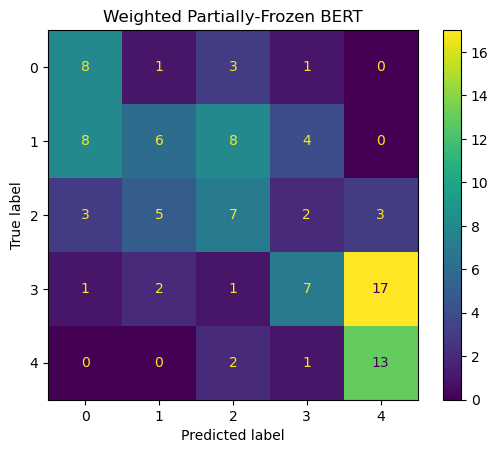

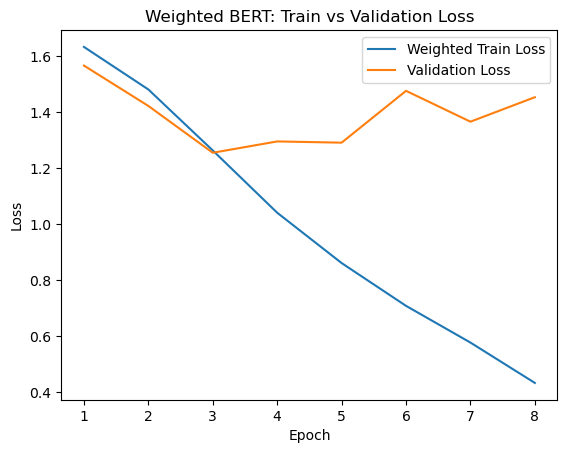

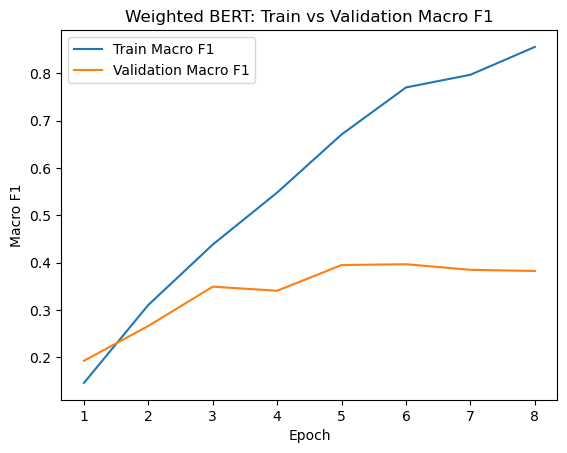

In [40]:
import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# SETTINGS
# ============================================================

MODEL_NAME = "google-bert/bert-base-uncased"
EPOCHS = 8


# ============================================================
# COMPUTE CLASS WEIGHTS FROM TRAINING DATA ONLY
# ============================================================

classes = np.array([0, 1, 2, 3, 4])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["Sentiment"]
)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

print("Class weights:")
for c, w in zip(classes, weights):
    print(f"Class {c}: {w:.4f}")


# ============================================================
# LOAD FRESH BERT
# ============================================================

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5,
    attn_implementation="eager"   # needed for MPS
).to(device)


# ============================================================
# FREEZE EMBEDDINGS + FIRST 8 / 12 BERT LAYERS
# Last 4 layers remain trainable
# ============================================================

for param in model.bert.embeddings.parameters():
    param.requires_grad = False

for layer in model.bert.encoder.layer[:8]:
    for param in layer.parameters():
        param.requires_grad = False


# ============================================================
# PARAMETER CHECK
# ============================================================

trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel()
    for p in model.parameters()
)

print("\nDevice:", device)
print(f"Trainable parameters: {trainable:,}")
print(f"Total parameters: {total:,}")
print(f"Trainable: {100 * trainable / total:.2f}%")


# ============================================================
# WEIGHTED LOSS
# ============================================================

weighted_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=2e-5,
    weight_decay=0.01
)


# ============================================================
# TRAIN FUNCTION — WEIGHTED LOSS
# ============================================================

def train_one_epoch_weighted(
    model,
    dataloader,
    optimizer,
    device,
    criterion
):
    model.train()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for batch in dataloader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        # Do NOT pass labels here,
        # because we calculate weighted loss ourselves
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        # Gradient clipping can help stabilize BERT
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(
            logits,
            dim=1
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

    avg_loss = total_loss / len(dataloader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return (
        avg_loss,
        accuracy,
        macro_f1
    )


# ============================================================
# EVALUATION FUNCTION
# Standard unweighted validation loss
# ============================================================

def evaluate(model, dataloader, device):

    model.eval()

    total_loss = 0.0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for batch in dataloader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            # Passing labels here gives ordinary CE loss
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_loss += outputs.loss.item()

            logits = outputs.logits

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    avg_loss = total_loss / len(dataloader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        all_labels,
        all_predictions
    )


# ============================================================
# TRAINING LOOP
# ============================================================

best_macro_f1 = -1
best_model_state = None
best_epoch = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_macro_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

for epoch in range(EPOCHS):

    (
        train_loss,
        train_accuracy,
        train_macro_f1
    ) = train_one_epoch_weighted(
        model,
        train_loader,
        optimizer,
        device,
        weighted_criterion
    )

    (
        val_loss,
        val_accuracy,
        val_macro_f1,
        _,
        _
    ) = evaluate(
        model,
        val_loader,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["train_macro_f1"].append(train_macro_f1)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_macro_f1)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Train F1: {train_macro_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_macro_f1:.4f}"
    )

    # Keep best validation Macro F1 model
    if val_macro_f1 > best_macro_f1:

        best_macro_f1 = val_macro_f1
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )


# ============================================================
# RESTORE BEST MODEL
# ============================================================

model.load_state_dict(
    best_model_state
)

model.to(device)


# ============================================================
# FINAL VALIDATION
# ============================================================

(
    val_loss,
    val_accuracy,
    val_macro_f1,
    y_true,
    y_pred
) = evaluate(
    model,
    val_loader,
    device
)

print("\n" + "=" * 55)
print("BEST WEIGHTED BERT RESULTS")
print("=" * 55)

print(f"Best Epoch: {best_epoch}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Macro F1: {val_macro_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        digits=3,
        zero_division=0
    )
)


# ============================================================
# OVERFITTING CHECK
# ============================================================

(
    _,
    train_accuracy_final,
    train_macro_f1_final,
    _,
    _
) = evaluate(
    model,
    train_loader,
    device
)

print("\n" + "=" * 55)
print("OVERFITTING CHECK")
print("=" * 55)

print(
    f"Train Accuracy:      "
    f"{train_accuracy_final:.4f}"
)

print(
    f"Train Macro F1:      "
    f"{train_macro_f1_final:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{val_accuracy:.4f}"
)

print(
    f"Validation Macro F1: "
    f"{val_macro_f1:.4f}"
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.title(
    "Weighted Partially-Frozen BERT"
)

plt.show()


# ============================================================
# LOSS CURVE
# ============================================================

plt.figure()

plt.plot(
    range(1, EPOCHS + 1),
    history["train_loss"],
    label="Weighted Train Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "Weighted BERT: Train vs Validation Loss"
)

plt.legend()
plt.show()


# ============================================================
# MACRO F1 CURVE
# ============================================================

plt.figure()

plt.plot(
    range(1, EPOCHS + 1),
    history["train_macro_f1"],
    label="Train Macro F1"
)

plt.plot(
    range(1, EPOCHS + 1),
    history["val_macro_f1"],
    label="Validation Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")

plt.title(
    "Weighted BERT: Train vs Validation Macro F1"
)

plt.legend()
plt.show()

class weight fixed class 0 partly by damaging classes 1 and 3.

Device: mps


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Model: DistilBERT
Trainable parameters: 14,770,181
Total parameters: 66,957,317
Trainable percentage: 22.06%
Epoch 1/8 | Train Loss: 1.5998 | Train Acc: 0.2230 | Train F1: 0.1375 | Val Loss: 1.5512 | Val Acc: 0.3204 | Val F1: 0.1523
Epoch 2/8 | Train Loss: 1.5118 | Train Acc: 0.3578 | Train F1: 0.1872 | Val Loss: 1.4501 | Val Acc: 0.3981 | Val F1: 0.2096
Epoch 3/8 | Train Loss: 1.3479 | Train Acc: 0.4510 | Train F1: 0.2962 | Val Loss: 1.3077 | Val Acc: 0.4369 | Val F1: 0.3046
Epoch 4/8 | Train Loss: 1.2050 | Train Acc: 0.4902 | Train F1: 0.3673 | Val Loss: 1.2187 | Val Acc: 0.4660 | Val F1: 0.3376
Epoch 5/8 | Train Loss: 1.0678 | Train Acc: 0.5882 | Train F1: 0.5268 | Val Loss: 1.2051 | Val Acc: 0.4466 | Val F1: 0.3414
Epoch 6/8 | Train Loss: 0.9724 | Train Acc: 0.6373 | Train F1: 0.5871 | Val Loss: 1.2080 | Val Acc: 0.4078 | Val F1: 0.3191
Epoch 7/8 | Train Loss: 0.8835 | Train Acc: 0.6642 | Train F1: 0.6214 | Val Loss: 1.2190 | Val Acc: 0.4369 | Val F1: 0.3885
Epoch 8/8 | Train Loss

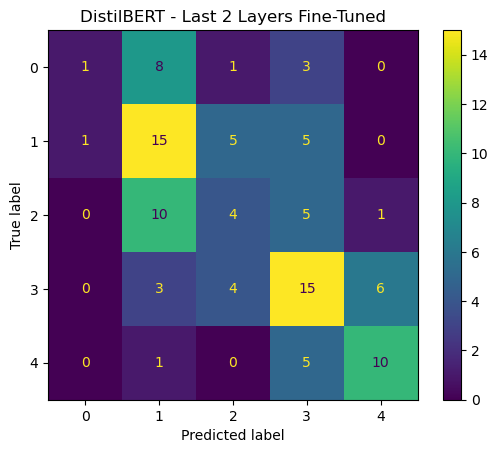

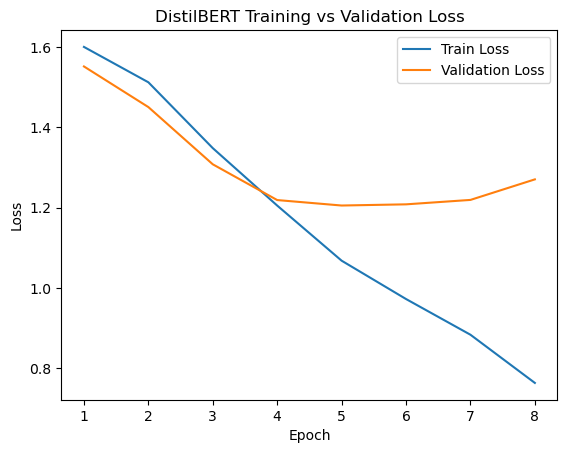

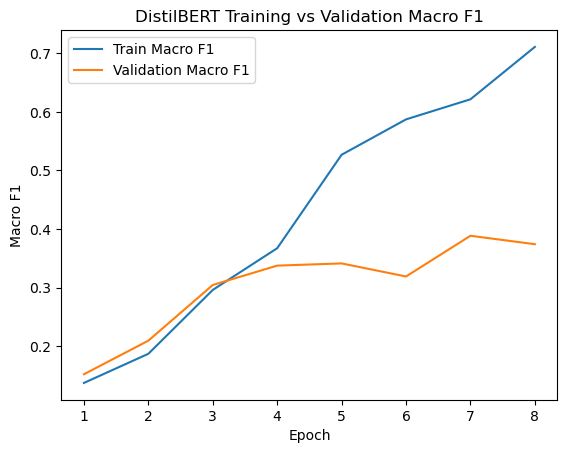

In [41]:
# ============================================================
# DISTILBERT TRANSFER LEARNING — ONE CELL
# Freeze first 4/6 transformer layers
# Fine-tune last 2 layers + classifier
# ============================================================

import copy
import torch
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# SETTINGS
# ============================================================

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 64
BATCH_SIZE = 8
EPOCHS = 8
PATIENCE = 2

# Device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)


# ============================================================
# TOKENIZER
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


# ============================================================
# DATASET
# ============================================================

class MovieReviewDataset(Dataset):

    def __init__(self, dataframe, tokenizer, max_length=64):
        self.texts = dataframe["Phrase"].astype(str).tolist()
        self.labels = dataframe["Sentiment"].astype(int).tolist()

        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids":
                encoding["input_ids"].squeeze(0),

            "attention_mask":
                encoding["attention_mask"].squeeze(0),

            "labels":
                torch.tensor(
                    self.labels[idx],
                    dtype=torch.long
                )
        }


train_dataset = MovieReviewDataset(
    train_df,
    tokenizer,
    MAX_LENGTH
)

val_dataset = MovieReviewDataset(
    val_df,
    tokenizer,
    MAX_LENGTH
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# ============================================================
# LOAD FRESH DISTILBERT
# ============================================================

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5,
    attn_implementation="eager"   # avoids MPS SDPA dropout issue
).to(device)


# ============================================================
# FREEZE EMBEDDINGS
# ============================================================

for param in model.distilbert.embeddings.parameters():
    param.requires_grad = False


# ============================================================
# FREEZE FIRST 4 / 6 TRANSFORMER LAYERS
#
# Frozen:
# Layer 0
# Layer 1
# Layer 2
# Layer 3
#
# Trainable:
# Layer 4
# Layer 5
# classifier
# ============================================================

for layer in model.distilbert.transformer.layer[:4]:

    for param in layer.parameters():
        param.requires_grad = False


# ============================================================
# PARAMETER CHECK
# ============================================================

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("\nModel: DistilBERT")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")
print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=2e-5,
    weight_decay=0.01
)


# ============================================================
# TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(
    model,
    dataloader,
    optimizer,
    device
):

    model.train()

    total_loss = 0

    all_labels = []
    all_predictions = []

    for batch in dataloader:

        input_ids = batch["input_ids"].to(device)

        attention_mask = (
            batch["attention_mask"].to(device)
        )

        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()

        # Stabilize training
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

    avg_loss = (
        total_loss / len(dataloader)
    )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return (
        avg_loss,
        accuracy,
        macro_f1
    )


# ============================================================
# EVALUATION
# ============================================================

def evaluate(
    model,
    dataloader,
    device
):

    model.eval()

    total_loss = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for batch in dataloader:

            input_ids = (
                batch["input_ids"].to(device)
            )

            attention_mask = (
                batch["attention_mask"].to(device)
            )

            labels = (
                batch["labels"].to(device)
            )

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_loss += (
                outputs.loss.item()
            )

            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    avg_loss = (
        total_loss / len(dataloader)
    )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        all_labels,
        all_predictions
    )


# ============================================================
# TRAINING LOOP + EARLY STOPPING
# ============================================================

best_macro_f1 = -1

best_model_state = None
best_epoch = 0

epochs_without_improvement = 0

history = {
    "train_loss": [],
    "train_f1": [],
    "val_loss": [],
    "val_f1": [],
    "val_accuracy": []
}


for epoch in range(EPOCHS):

    (
        train_loss,
        train_accuracy,
        train_f1
    ) = train_one_epoch(
        model,
        train_loader,
        optimizer,
        device
    )

    (
        val_loss,
        val_accuracy,
        val_f1,
        _,
        _
    ) = evaluate(
        model,
        val_loader,
        device
    )

    history["train_loss"].append(
        train_loss
    )

    history["train_f1"].append(
        train_f1
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_f1"].append(
        val_f1
    )

    history["val_accuracy"].append(
        val_accuracy
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    # --------------------------
    # Save best model
    # --------------------------

    if val_f1 > best_macro_f1:

        best_macro_f1 = val_f1

        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    # --------------------------
    # Early stopping
    # --------------------------

    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping at epoch "
            f"{epoch + 1}"
        )

        break


# ============================================================
# RESTORE BEST MODEL
# ============================================================

model.load_state_dict(
    best_model_state
)

model.to(device)


# ============================================================
# FINAL VALIDATION RESULTS
# ============================================================

(
    val_loss,
    val_accuracy,
    val_macro_f1,
    y_true,
    y_pred
) = evaluate(
    model,
    val_loader,
    device
)


print("\n" + "=" * 55)

print(
    "BEST DISTILBERT RESULTS"
)

print("=" * 55)

print(
    f"Best Epoch: {best_epoch}"
)

print(
    f"Validation Loss: "
    f"{val_loss:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{val_accuracy:.4f}"
)

print(
    f"Validation Macro F1: "
    f"{val_macro_f1:.4f}"
)


print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        digits=3,
        zero_division=0
    )
)


# ============================================================
# OVERFITTING CHECK
# ============================================================

(
    _,
    train_accuracy,
    train_macro_f1,
    _,
    _
) = evaluate(
    model,
    train_loader,
    device
)


print("\n" + "=" * 55)

print(
    "OVERFITTING CHECK"
)

print("=" * 55)

print(
    f"Train Accuracy:      "
    f"{train_accuracy:.4f}"
)

print(
    f"Train Macro F1:      "
    f"{train_macro_f1:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{val_accuracy:.4f}"
)

print(
    f"Validation Macro F1: "
    f"{val_macro_f1:.4f}"
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.title(
    "DistilBERT - Last 2 Layers Fine-Tuned"
)

plt.show()


# ============================================================
# LOSS CURVE
# ============================================================

epochs_ran = len(
    history["train_loss"]
)

plt.figure()

plt.plot(
    range(1, epochs_ran + 1),
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    range(1, epochs_ran + 1),
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "DistilBERT Training vs Validation Loss"
)

plt.legend()

plt.show()


# ============================================================
# MACRO F1 CURVE
# ============================================================

plt.figure()

plt.plot(
    range(1, epochs_ran + 1),
    history["train_f1"],
    label="Train Macro F1"
)

plt.plot(
    range(1, epochs_ran + 1),
    history["val_f1"],
    label="Validation Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")

plt.title(
    "DistilBERT Training vs Validation Macro F1"
)

plt.legend()

plt.show()

Vocabulary size: 2443
Reservoir spectral radius: 0.8999999

Creating training reservoir states...
Creating validation reservoir states...

Reservoir feature shape: (408, 64)

ECHO STATE NETWORK RESULTS
Train Accuracy:      0.4877
Train Macro F1:      0.4764
Validation Accuracy: 0.2621
Validation Macro F1: 0.1869

Classification Report:
              precision    recall  f1-score   support

           0      0.167     0.077     0.105        13
           1      0.253     0.731     0.376        26
           2      0.250     0.100     0.143        20
           3      0.364     0.143     0.205        28
           4      0.333     0.062     0.105        16

    accuracy                          0.262       103
   macro avg      0.273     0.223     0.187       103
weighted avg      0.284     0.262     0.208       103



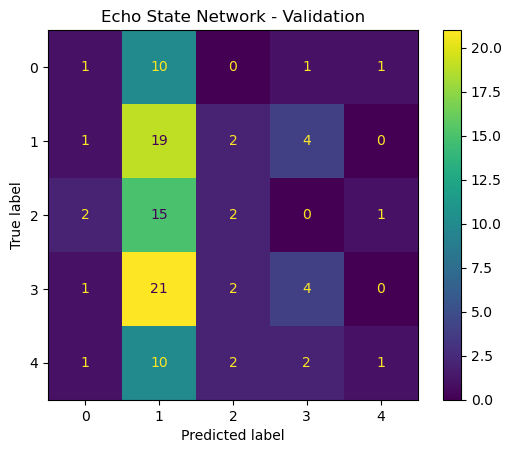

In [51]:
# ============================================================
# RESERVOIR COMPUTING / ECHO STATE NETWORK FOR SENTIMENT
# One-cell implementation
# ============================================================

import re
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)


# ============================================================
# SETTINGS
# ============================================================

RANDOM_STATE = 42

RESERVOIR_SIZE = 32
SPECTRAL_RADIUS = 0.90
LEAK_RATE = 0.50
INPUT_SCALE = 0.50
SPARSITY = 0.10

MAX_VOCAB = 3000
MIN_FREQ = 1

rng = np.random.default_rng(RANDOM_STATE)


# ============================================================
# SIMPLE TOKENIZER
# ============================================================

def tokenize(text):
    text = str(text).lower()

    # Keep words and contractions
    return re.findall(
        r"[a-z]+(?:'[a-z]+)?",
        text
    )


# ============================================================
# BUILD VOCABULARY FROM TRAINING DATA ONLY
# ============================================================

word_counts = Counter()

for text in train_df["Phrase"]:
    word_counts.update(tokenize(text))


most_common = [
    word
    for word, count in word_counts.most_common(MAX_VOCAB)
    if count >= MIN_FREQ
]

word2idx = {
    word: idx + 1
    for idx, word in enumerate(most_common)
}

# 0 reserved for unknown words
VOCAB_SIZE = len(word2idx) + 1

print("Vocabulary size:", VOCAB_SIZE)


# ============================================================
# RANDOM INPUT WEIGHTS
#
# Each word gets a fixed random vector that feeds the reservoir.
# These weights are NOT trained.
# ============================================================

W_in = rng.uniform(
    low=-INPUT_SCALE,
    high=INPUT_SCALE,
    size=(VOCAB_SIZE, RESERVOIR_SIZE)
).astype(np.float32)


# ============================================================
# RANDOM RECURRENT RESERVOIR
# ============================================================

W_res = rng.uniform(
    low=-1.0,
    high=1.0,
    size=(RESERVOIR_SIZE, RESERVOIR_SIZE)
).astype(np.float32)


# Make reservoir sparse
mask = (
    rng.random(
        (RESERVOIR_SIZE, RESERVOIR_SIZE)
    )
    < SPARSITY
)

W_res *= mask


# ============================================================
# SCALE TO DESIRED SPECTRAL RADIUS
# ============================================================

eigenvalues = np.linalg.eigvals(W_res)

current_radius = np.max(
    np.abs(eigenvalues)
)

if current_radius > 0:
    W_res *= (
        SPECTRAL_RADIUS /
        current_radius
    )

print(
    "Reservoir spectral radius:",
    np.max(
        np.abs(
            np.linalg.eigvals(W_res)
        )
    )
)


# ============================================================
# RUN ONE REVIEW THROUGH RESERVOIR
# ============================================================

def reservoir_features(text):

    tokens = tokenize(text)

    # Empty review fallback
    if len(tokens) == 0:
        return np.zeros(
            RESERVOIR_SIZE * 2,
            dtype=np.float32
        )

    state = np.zeros(
        RESERVOIR_SIZE,
        dtype=np.float32
    )

    states = []

    for token in tokens:

        idx = word2idx.get(
            token,
            0
        )

        input_vector = W_in[idx]

        new_state = np.tanh(
            input_vector
            +
            W_res @ state
        )

        # Leaky integration
        state = (
            (1 - LEAK_RATE) * state
            +
            LEAK_RATE * new_state
        )

        states.append(
            state.copy()
        )

    states = np.array(states)

    # Two representations:
    # 1. final reservoir state
    # 2. mean state over the review
    final_state = states[-1]

    mean_state = states.mean(
        axis=0
    )

    return np.concatenate(
        [
            final_state,
            mean_state
        ]
    )


# ============================================================
# CREATE RESERVOIR FEATURES
# ============================================================

print("\nCreating training reservoir states...")

X_train_res = np.vstack([
    reservoir_features(text)
    for text in train_df["Phrase"]
])

print("Creating validation reservoir states...")

X_val_res = np.vstack([
    reservoir_features(text)
    for text in val_df["Phrase"]
])

y_train = train_df[
    "Sentiment"
].to_numpy()

y_val = val_df[
    "Sentiment"
].to_numpy()

print(
    "\nReservoir feature shape:",
    X_train_res.shape
)


# ============================================================
# TRAIN READOUT LAYER
#
# Reservoir is FIXED.
# Only this classifier is trained.
# ============================================================

readout = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),

    (
        "classifier",
        LogisticRegression(
            max_iter=5000,
            C=0.1,
            random_state=RANDOM_STATE
        )
    )
])


readout.fit(
    X_train_res,
    y_train
)


# ============================================================
# VALIDATION PREDICTION
# ============================================================

val_pred = readout.predict(
    X_val_res
)

val_accuracy = accuracy_score(
    y_val,
    val_pred
)

val_macro_f1 = f1_score(
    y_val,
    val_pred,
    average="macro",
    zero_division=0
)


# ============================================================
# TRAIN PERFORMANCE
# ============================================================

train_pred = readout.predict(
    X_train_res
)

train_accuracy = accuracy_score(
    y_train,
    train_pred
)

train_macro_f1 = f1_score(
    y_train,
    train_pred,
    average="macro",
    zero_division=0
)


# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 55)
print("ECHO STATE NETWORK RESULTS")
print("=" * 55)

print(
    f"Train Accuracy:      "
    f"{train_accuracy:.4f}"
)

print(
    f"Train Macro F1:      "
    f"{train_macro_f1:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{val_accuracy:.4f}"
)

print(
    f"Validation Macro F1: "
    f"{val_macro_f1:.4f}"
)


print("\nClassification Report:")

print(
    classification_report(
        y_val,
        val_pred,
        digits=3,
        zero_division=0
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.title(
    "Echo State Network - Validation"
)

plt.show()

Device: mps
Mamba parameters: 129,135,360
Trainable Mamba parameters: 0

Extracting TRAIN Mamba features...
Processed 408/408
Train feature shape: (408, 768)

Extracting VALIDATION Mamba features...
Processed 103/103
Validation feature shape: (103, 768)

PRETRAINED MAMBA RESULTS
Train Accuracy:      0.9853
Train Macro F1:      0.9861
Validation Accuracy: 0.3883
Validation Macro F1: 0.3518

Classification Report:
              precision    recall  f1-score   support

           0      0.083     0.077     0.080        13
           1      0.484     0.577     0.526        26
           2      0.235     0.200     0.216        20
           3      0.444     0.429     0.436        28
           4      0.500     0.500     0.500        16

    accuracy                          0.388       103
   macro avg      0.349     0.356     0.352       103
weighted avg      0.377     0.388     0.381       103



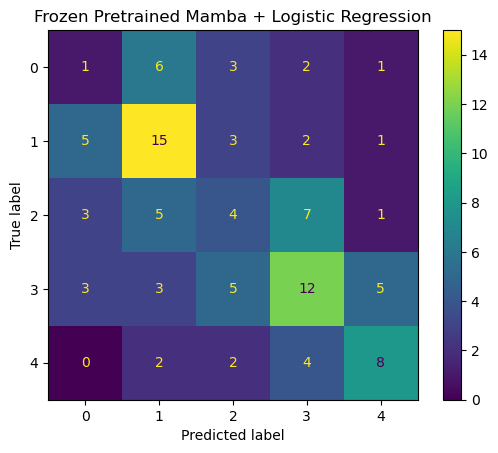

In [55]:
# ============================================================
# PRETRAINED MAMBA + LOGISTIC REGRESSION
# Frozen Mamba feature extractor
# ============================================================

import numpy as np
import torch
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, MambaModel

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# SETTINGS
# ============================================================

MODEL_NAME = "state-spaces/mamba-130m-hf"

MAX_LENGTH = 64
BATCH_SIZE = 8

# Stronger regularization because dataset is tiny
C = 0.05

# MPS if available
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)


# ============================================================
# TOKENIZER
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

# Ensure padding token exists
if tokenizer.pad_token_id is None:
    if tokenizer.eos_token is not None:
        tokenizer.pad_token = tokenizer.eos_token
    else:
        tokenizer.pad_token = tokenizer.unk_token


# ============================================================
# LOAD PRETRAINED MAMBA
# ============================================================

mamba = MambaModel.from_pretrained(
    MODEL_NAME
).to(device)

# We are NOT fine-tuning Mamba
for param in mamba.parameters():
    param.requires_grad = False

mamba.eval()

print(
    f"Mamba parameters: "
    f"{sum(p.numel() for p in mamba.parameters()):,}"
)

print(
    "Trainable Mamba parameters:",
    sum(
        p.numel()
        for p in mamba.parameters()
        if p.requires_grad
    )
)


# ============================================================
# FEATURE EXTRACTION
# ============================================================

def extract_mamba_features(texts):

    all_features = []

    texts = list(texts)

    for start in range(
        0,
        len(texts),
        BATCH_SIZE
    ):

        batch_texts = texts[
            start:start + BATCH_SIZE
        ]

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        input_ids = (
            encoded["input_ids"]
            .to(device)
        )

        attention_mask = (
            encoded["attention_mask"]
            .to(device)
        )

        with torch.no_grad():

            outputs = mamba(
                input_ids=input_ids,
                attention_mask=attention_mask,
                use_cache=False,
                return_dict=True
            )

            # Shape:
            # batch x sequence_length x hidden_size
            hidden = outputs.last_hidden_state

            # --------------------------------------------
            # Mean pooling over NON-PADDING tokens
            # --------------------------------------------

            mask = (
                attention_mask
                .unsqueeze(-1)
                .to(hidden.dtype)
            )

            pooled = (
                (hidden * mask).sum(dim=1)
                /
                mask.sum(dim=1).clamp(min=1e-9)
            )

        all_features.append(
            pooled.cpu().numpy()
        )

        print(
            f"\rProcessed "
            f"{min(start + BATCH_SIZE, len(texts))}"
            f"/{len(texts)}",
            end=""
        )

    print()

    return np.vstack(
        all_features
    )


# ============================================================
# EXTRACT TRAIN FEATURES
# ============================================================

print("\nExtracting TRAIN Mamba features...")

X_train_mamba = extract_mamba_features(
    train_df["Phrase"]
)

print(
    "Train feature shape:",
    X_train_mamba.shape
)


# ============================================================
# EXTRACT VALIDATION FEATURES
# ============================================================

print("\nExtracting VALIDATION Mamba features...")

X_val_mamba = extract_mamba_features(
    val_df["Phrase"]
)

print(
    "Validation feature shape:",
    X_val_mamba.shape
)


# ============================================================
# LABELS
# ============================================================

y_train = (
    train_df["Sentiment"]
    .to_numpy()
)

y_val = (
    val_df["Sentiment"]
    .to_numpy()
)


# ============================================================
# TRAIN CLASSIFIER
# ============================================================

classifier = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),

    (
        "classifier",
        LogisticRegression(
            C=C,
            max_iter=5000,
            random_state=42
        )
    )
])

classifier.fit(
    X_train_mamba,
    y_train
)


# ============================================================
# PREDICTIONS
# ============================================================

train_pred = classifier.predict(
    X_train_mamba
)

val_pred = classifier.predict(
    X_val_mamba
)


# ============================================================
# METRICS
# ============================================================

train_accuracy = accuracy_score(
    y_train,
    train_pred
)

train_f1 = f1_score(
    y_train,
    train_pred,
    average="macro",
    zero_division=0
)

val_accuracy = accuracy_score(
    y_val,
    val_pred
)

val_f1 = f1_score(
    y_val,
    val_pred,
    average="macro",
    zero_division=0
)


# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 55)
print("PRETRAINED MAMBA RESULTS")
print("=" * 55)

print(
    f"Train Accuracy:      "
    f"{train_accuracy:.4f}"
)

print(
    f"Train Macro F1:      "
    f"{train_f1:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{val_accuracy:.4f}"
)

print(
    f"Validation Macro F1: "
    f"{val_f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        y_val,
        val_pred,
        digits=3,
        zero_division=0
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.title(
    "Frozen Pretrained Mamba + Logistic Regression"
)

plt.show()

Device: mps
Mamba parameters: 129,135,360
Trainable Mamba parameters: 0

Extracting TRAIN last-token Mamba features...
Processed 408/408
Train feature shape: (408, 768)

Extracting VALIDATION last-token Mamba features...
Processed 103/103
Validation feature shape: (103, 768)

MAMBA LAST-TOKEN POOLING RESULTS
Train Accuracy:      0.9730
Train Macro F1:      0.9760
Validation Accuracy: 0.3981
Validation Macro F1: 0.3821

Classification Report:
              precision    recall  f1-score   support

           0      0.300     0.231     0.261        13
           1      0.375     0.462     0.414        26
           2      0.304     0.350     0.326        20
           3      0.500     0.464     0.481        28
           4      0.500     0.375     0.429        16

    accuracy                          0.398       103
   macro avg      0.396     0.376     0.382       103
weighted avg      0.405     0.398     0.398       103



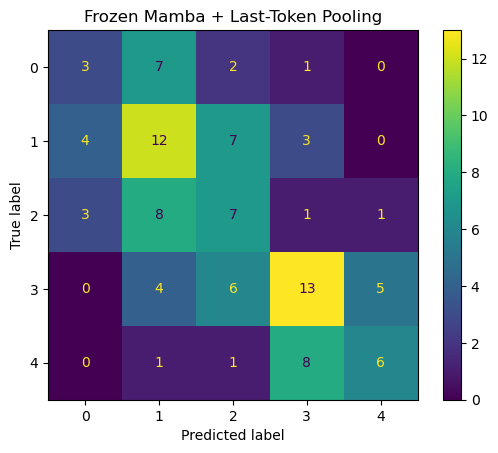

In [56]:
# ============================================================
# PRETRAINED MAMBA + LAST-TOKEN POOLING + LOGISTIC REGRESSION
# Frozen Mamba feature extractor
# ============================================================

import numpy as np
import torch
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, MambaModel

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# SETTINGS
# ============================================================

MODEL_NAME = "state-spaces/mamba-130m-hf"

MAX_LENGTH = 64
BATCH_SIZE = 8
C = 0.1

# Device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)


# ============================================================
# TOKENIZER
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

# Ensure padding token exists
if tokenizer.pad_token_id is None:
    if tokenizer.eos_token is not None:
        tokenizer.pad_token = tokenizer.eos_token
    else:
        tokenizer.pad_token = tokenizer.unk_token


# ============================================================
# LOAD PRETRAINED MAMBA
# ============================================================

mamba = MambaModel.from_pretrained(
    MODEL_NAME
).to(device)

# Freeze Mamba completely
for param in mamba.parameters():
    param.requires_grad = False

mamba.eval()

print(
    f"Mamba parameters: "
    f"{sum(p.numel() for p in mamba.parameters()):,}"
)

print(
    "Trainable Mamba parameters:",
    sum(
        p.numel()
        for p in mamba.parameters()
        if p.requires_grad
    )
)


# ============================================================
# FEATURE EXTRACTION WITH LAST-TOKEN POOLING
# ============================================================

def extract_mamba_last_token_features(texts):

    all_features = []

    texts = list(texts)

    for start in range(
        0,
        len(texts),
        BATCH_SIZE
    ):

        batch_texts = texts[
            start:start + BATCH_SIZE
        ]

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        input_ids = (
            encoded["input_ids"]
            .to(device)
        )

        attention_mask = (
            encoded["attention_mask"]
            .to(device)
        )

        with torch.no_grad():

            outputs = mamba(
                input_ids=input_ids,
                attention_mask=attention_mask,
                use_cache=False,
                return_dict=True
            )

            # Shape:
            # [batch_size, sequence_length, hidden_size]
            hidden = outputs.last_hidden_state

            # --------------------------------------------
            # LAST VALID TOKEN FOR EACH SEQUENCE
            # --------------------------------------------

            last_token_index = (
                attention_mask.sum(dim=1) - 1
            )

            batch_indices = torch.arange(
                hidden.size(0),
                device=hidden.device
            )

            pooled = hidden[
                batch_indices,
                last_token_index
            ]

        all_features.append(
            pooled.cpu().numpy()
        )

        print(
            f"\rProcessed "
            f"{min(start + BATCH_SIZE, len(texts))}"
            f"/{len(texts)}",
            end=""
        )

    print()

    return np.vstack(
        all_features
    )


# ============================================================
# EXTRACT TRAIN FEATURES
# ============================================================

print("\nExtracting TRAIN last-token Mamba features...")

X_train_mamba = extract_mamba_last_token_features(
    train_df["Phrase"]
)

print(
    "Train feature shape:",
    X_train_mamba.shape
)


# ============================================================
# EXTRACT VALIDATION FEATURES
# ============================================================

print("\nExtracting VALIDATION last-token Mamba features...")

X_val_mamba = extract_mamba_last_token_features(
    val_df["Phrase"]
)

print(
    "Validation feature shape:",
    X_val_mamba.shape
)


# ============================================================
# LABELS
# ============================================================

y_train = (
    train_df["Sentiment"]
    .to_numpy()
)

y_val = (
    val_df["Sentiment"]
    .to_numpy()
)


# ============================================================
# LOGISTIC REGRESSION READOUT
# ============================================================

classifier = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),

    (
        "classifier",
        LogisticRegression(
            C=C,
            max_iter=5000,
            random_state=42
        )
    )
])

classifier.fit(
    X_train_mamba,
    y_train
)


# ============================================================
# PREDICTIONS
# ============================================================

train_pred = classifier.predict(
    X_train_mamba
)

val_pred = classifier.predict(
    X_val_mamba
)


# ============================================================
# METRICS
# ============================================================

train_accuracy = accuracy_score(
    y_train,
    train_pred
)

train_f1 = f1_score(
    y_train,
    train_pred,
    average="macro",
    zero_division=0
)

val_accuracy = accuracy_score(
    y_val,
    val_pred
)

val_f1 = f1_score(
    y_val,
    val_pred,
    average="macro",
    zero_division=0
)


# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 55)
print("MAMBA LAST-TOKEN POOLING RESULTS")
print("=" * 55)

print(
    f"Train Accuracy:      "
    f"{train_accuracy:.4f}"
)

print(
    f"Train Macro F1:      "
    f"{train_f1:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{val_accuracy:.4f}"
)

print(
    f"Validation Macro F1: "
    f"{val_f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        y_val,
        val_pred,
        digits=3,
        zero_division=0
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.title(
    "Frozen Mamba + Last-Token Pooling"
)

plt.show()

In [58]:
%pip install --force-reinstall \
    "numpy==1.26.4" \
    "fsspec==2025.3.0" \
    "torchvision==0.29.0"

  Using cached numpy-1.26.4-cp311-cp311-macosx_11_0_arm64.whl.metadata (114 kB)
  Using cached torch-2.14.0-cp311-cp311-macosx_14_0_arm64.whl.metadata (38 kB)
  Using cached pillow-12.3.0-cp311-cp311-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached filelock-4.2.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached markupsafe-3.0.4-cp311-cp311-macosx_11_0_arm64.whl.metadata (2.7 kB)
Using cached numpy-1.26.4-cp311-cp311-macosx_11_0_arm64.whl (14.0 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 9.3 MB/s  0:00:00 eta 0:00:01
Using cached torch-2.14.0-cp311-cp311-macosx_14_0_arm64.whl 

In [2]:
import pandas
train = pandas.read_csv('train.csv')
test = pandas.read_csv('test.csv')
#Stratified split
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train,
    test_size=0.2,
    random_state=42,
    stratify=train["Sentiment"]
)

TF-IDF train shape: (408, 7744)
SVD train shape: (408, 10)
Explained variance: 0.0424

Bayesian Network fitted.
Model valid: True
Nodes: ['Sentiment', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'F9', 'F10']
Edges: [('Sentiment', 'F1'), ('Sentiment', 'F2'), ('Sentiment', 'F3'), ('Sentiment', 'F4'), ('Sentiment', 'F5'), ('Sentiment', 'F6'), ('Sentiment', 'F7'), ('Sentiment', 'F8'), ('Sentiment', 'F9'), ('Sentiment', 'F10')]


/opt/anaconda3/envs/dml/lib/python3.11/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
/var/folders/k_/643yxrvd3xxb0md9scf224bc0000gp/T/ipykernel_71329/1656804726.py:166: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(



BAYESIAN NETWORK RESULTS
Train Accuracy:      0.3529
Train Macro F1:      0.3259
Validation Accuracy: 0.2816
Validation Macro F1: 0.2517

Classification Report:
              precision    recall  f1-score   support

           0      0.188     0.231     0.207        13
           1      0.222     0.231     0.226        26
           2      0.350     0.350     0.350        20
           3      0.333     0.429     0.375        28
           4      0.250     0.062     0.100        16

    accuracy                          0.282       103
   macro avg      0.269     0.261     0.252       103
weighted avg      0.277     0.282     0.269       103



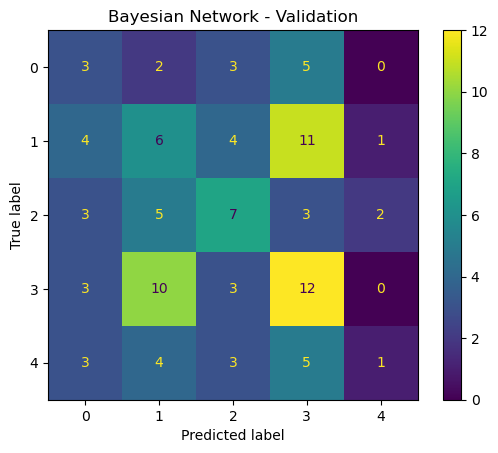


EXAMPLE POSTERIOR

Review:
than ` Magnifique ' .

True sentiment: 2
Predicted sentiment: 1

Posterior probabilities:
P(Sentiment=0 | review) = 0.1515
P(Sentiment=1 | review) = 0.3698
P(Sentiment=2 | review) = 0.1408
P(Sentiment=3 | review) = 0.2025
P(Sentiment=4 | review) = 0.1354


In [8]:
# ============================================================
# BAYESIAN NETWORK FOR MOVIE SENTIMENT — ONE CELL
# TF-IDF -> SVD -> Discretization -> Bayesian Network
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import KBinsDiscretizer

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination


# ============================================================
# SETTINGS
# ============================================================

N_COMPONENTS = 10
N_BINS = 3
RANDOM_STATE = 42
EQUIVALENT_SAMPLE_SIZE = 10


# ============================================================
# LABELS
# ============================================================

y_train = train_df["Sentiment"].astype(int).to_numpy()
y_val = val_df["Sentiment"].astype(int).to_numpy()


# ============================================================
# 1. TF-IDF
# Fit only on training data
# ============================================================

tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(
    train_df["Phrase"]
)

X_val_tfidf = tfidf.transform(
    val_df["Phrase"]
)

print("TF-IDF train shape:", X_train_tfidf.shape)


# ============================================================
# 2. SVD
# Reduce sparse TF-IDF to a small dense representation
# ============================================================

svd = TruncatedSVD(
    n_components=N_COMPONENTS,
    random_state=RANDOM_STATE
)

X_train_svd = svd.fit_transform(
    X_train_tfidf
)

X_val_svd = svd.transform(
    X_val_tfidf
)

print("SVD train shape:", X_train_svd.shape)

print(
    "Explained variance:",
    round(
        svd.explained_variance_ratio_.sum(),
        4
    )
)


# ============================================================
# 3. DISCRETIZATION
#
# Each SVD feature becomes:
# 0 = low
# 1 = medium
# 2 = high
# ============================================================

discretizer = KBinsDiscretizer(
    n_bins=N_BINS,
    encode="ordinal",
    strategy="quantile",
    subsample=None
)

X_train_disc = discretizer.fit_transform(
    X_train_svd
).astype(int)

X_val_disc = discretizer.transform(
    X_val_svd
).astype(int)


# ============================================================
# 4. CREATE BAYESIAN-NETWORK DATAFRAME
# ============================================================

feature_names = [
    f"F{i+1}"
    for i in range(N_COMPONENTS)
]

train_bn = pd.DataFrame(
    X_train_disc,
    columns=feature_names
)

train_bn["Sentiment"] = y_train


# ============================================================
# 5. DEFINE NETWORK STRUCTURE
#
#               Sentiment
#             /    |     \
#           F1    F2 ... F8
#
# Sentiment is the parent;
# latent text features are children.
# ============================================================

edges = [
    ("Sentiment", feature)
    for feature in feature_names
]

model = DiscreteBayesianNetwork(
    edges
)


# ============================================================
# 6. BAYESIAN PARAMETER ESTIMATION
#
# Explicit BayesianEstimator used because some pgmpy
# versions do not accept prior_type directly in model.fit()
# ============================================================

estimator = BayesianEstimator(
    model=model,
    data=train_bn
)

cpds = estimator.get_parameters(
    prior_type="BDeu",
    equivalent_sample_size=EQUIVALENT_SAMPLE_SIZE
)

model.add_cpds(*cpds)

print("\nBayesian Network fitted.")
print("Model valid:", model.check_model())
print("Nodes:", list(model.nodes()))
print("Edges:", list(model.edges()))


# ============================================================
# 7. INFERENCE ENGINE
# ============================================================

inference = VariableElimination(
    model
)


# ============================================================
# 8. PREDICTION FUNCTION
# ============================================================

def predict_bn(X_discrete):

    predictions = []
    probabilities = []

    for row in X_discrete:

        evidence = {
            feature_names[i]: int(row[i])
            for i in range(N_COMPONENTS)
        }

        result = inference.query(
            variables=["Sentiment"],
            evidence=evidence,
            show_progress=False
        )

        probs = np.asarray(
            result.values,
            dtype=float
        )

        # Retrieve actual state labels safely
        sentiment_states = result.state_names["Sentiment"]

        pred_index = np.argmax(probs)

        pred = int(
            sentiment_states[pred_index]
        )

        predictions.append(pred)
        probabilities.append(probs)

    return (
        np.array(predictions),
        np.array(probabilities)
    )


# ============================================================
# 9. TRAIN PREDICTIONS
# ============================================================

train_pred, train_prob = predict_bn(
    X_train_disc
)


# ============================================================
# 10. VALIDATION PREDICTIONS
# ============================================================

val_pred, val_prob = predict_bn(
    X_val_disc
)


# ============================================================
# 11. METRICS
# ============================================================

train_accuracy = accuracy_score(
    y_train,
    train_pred
)

train_macro_f1 = f1_score(
    y_train,
    train_pred,
    average="macro",
    zero_division=0
)

val_accuracy = accuracy_score(
    y_val,
    val_pred
)

val_macro_f1 = f1_score(
    y_val,
    val_pred,
    average="macro",
    zero_division=0
)


# ============================================================
# 12. RESULTS
# ============================================================

print("\n" + "=" * 55)
print("BAYESIAN NETWORK RESULTS")
print("=" * 55)

print(
    f"Train Accuracy:      "
    f"{train_accuracy:.4f}"
)

print(
    f"Train Macro F1:      "
    f"{train_macro_f1:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{val_accuracy:.4f}"
)

print(
    f"Validation Macro F1: "
    f"{val_macro_f1:.4f}"
)


print("\nClassification Report:")

print(
    classification_report(
        y_val,
        val_pred,
        digits=3,
        zero_division=0
    )
)


# ============================================================
# 13. CONFUSION MATRIX
# ============================================================

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.title(
    "Bayesian Network - Validation"
)

plt.show()


# ============================================================
# 14. EXAMPLE POSTERIOR
# ============================================================

example_index = 0

print("\n" + "=" * 55)
print("EXAMPLE POSTERIOR")
print("=" * 55)

print("\nReview:")
print(
    val_df.iloc[example_index]["Phrase"]
)

print(
    "\nTrue sentiment:",
    y_val[example_index]
)

print(
    "Predicted sentiment:",
    val_pred[example_index]
)

print("\nPosterior probabilities:")

for sentiment, probability in zip(
    model.get_cpds("Sentiment").state_names["Sentiment"],
    val_prob[example_index]
):

    print(
        f"P(Sentiment={sentiment} | review)"
        f" = {probability:.4f}"
    )

In [3]:
# ============================================================
# CONTEXTUAL PARAPHRASE AUGMENTATION USING BART
#
# No SentencePiece required
# No Tiktoken required
#
# Input:
#   train_df
#
# Output:
#   augmented_train_df
#
# Only classes 0, 2, 4 are augmented.
# val_df is NOT touched.
# ============================================================

import random
import numpy as np
import pandas as pd
import torch

from transformers import (
    BartTokenizer,
    BartForConditionalGeneration
)

# ============================================================
# SETTINGS
# ============================================================

MODEL_NAME = "eugenesiow/bart-paraphrase"

RANDOM_SEED = 42

# Target counts for minority classes
TARGET_COUNTS = {
    0: 100,   # Negative
    2: 100,   # Neutral
    4: 100    # Positive
}

MAX_LENGTH = 64
NUM_CANDIDATES = 4

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)


# ============================================================
# DEVICE
# ============================================================

if torch.cuda.is_available():
    device = torch.device("cuda")

elif torch.backends.mps.is_available():
    device = torch.device("mps")

else:
    device = torch.device("cpu")

print("Device:", device)


# ============================================================
# ORIGINAL DISTRIBUTION
# ============================================================

print("\nOriginal training distribution:")

print(
    train_df["Sentiment"]
    .value_counts()
    .sort_index()
)


# ============================================================
# LOAD BART TOKENIZER
# ============================================================

print("\nLoading BART tokenizer...")

tokenizer = BartTokenizer.from_pretrained(
    MODEL_NAME
)

print("Tokenizer loaded.")


# ============================================================
# LOAD BART PARAPHRASE MODEL
# ============================================================

print("\nLoading BART paraphrase model...")

paraphrase_model = (
    BartForConditionalGeneration
    .from_pretrained(MODEL_NAME)
    .to(device)
)

paraphrase_model.eval()

print("Model loaded.")


# ============================================================
# NEGATION CHECK
# ============================================================

NEGATION_WORDS = [
    "not",
    "no",
    "never",
    "n't",
    "neither",
    "nor",
    "without"
]


def has_negation(text):

    text = str(text).lower()

    return any(
        word in text
        for word in NEGATION_WORDS
    )


# ============================================================
# SIMPLE SIMILARITY FUNCTION
#
# Used only as a safety filter to reject paraphrases
# that become too different from the original.
# ============================================================

def word_overlap(original, paraphrase):

    original_words = set(
        str(original)
        .lower()
        .split()
    )

    paraphrase_words = set(
        str(paraphrase)
        .lower()
        .split()
    )

    if len(original_words) == 0:
        return 0

    intersection = (
        original_words
        &
        paraphrase_words
    )

    union = (
        original_words
        |
        paraphrase_words
    )

    return len(intersection) / max(
        len(union),
        1
    )


# ============================================================
# VALIDATION FILTER
# ============================================================

def valid_paraphrase(
    original,
    paraphrase
):

    original = str(original).strip()

    paraphrase = str(paraphrase).strip()

    original_lower = original.lower()
    paraphrase_lower = paraphrase.lower()


    # --------------------------------------------
    # Empty
    # --------------------------------------------

    if not paraphrase_lower:
        return False


    # --------------------------------------------
    # Exact same sentence
    # --------------------------------------------

    if paraphrase_lower == original_lower:
        return False


    original_words = original_lower.split()

    paraphrase_words = paraphrase_lower.split()


    # --------------------------------------------
    # Too short
    # --------------------------------------------

    if len(paraphrase_words) < 3:
        return False


    # --------------------------------------------
    # Length difference
    # --------------------------------------------

    ratio = (
        len(paraphrase_words)
        /
        max(len(original_words), 1)
    )

    if ratio < 0.5:
        return False

    if ratio > 2.0:
        return False


    # --------------------------------------------
    # Preserve negation
    # --------------------------------------------

    if (
        has_negation(original)
        and
        not has_negation(paraphrase)
    ):
        return False


    # --------------------------------------------
    # Reject extremely unrelated generations
    # --------------------------------------------

    overlap = word_overlap(
        original,
        paraphrase
    )

    if overlap < 0.10:
        return False


    return True


# ============================================================
# PARAPHRASE GENERATOR
# ============================================================

@torch.no_grad()
def generate_paraphrases(text):

    text = str(text).strip()

    encoded = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )

    input_ids = (
        encoded["input_ids"]
        .to(device)
    )

    attention_mask = (
        encoded["attention_mask"]
        .to(device)
    )


    outputs = paraphrase_model.generate(

        input_ids=input_ids,

        attention_mask=attention_mask,

        max_length=MAX_LENGTH,

        num_return_sequences=NUM_CANDIDATES,

        # Sampling for diverse paraphrases
        do_sample=True,

        temperature=0.85,

        top_p=0.92,

        top_k=50,

        repetition_penalty=1.1,

        no_repeat_ngram_size=2
    )


    paraphrases = tokenizer.batch_decode(
        outputs,
        skip_special_tokens=True
    )


    # Remove duplicate candidates
    unique = []

    seen = set()

    for sentence in paraphrases:

        sentence = sentence.strip()

        key = sentence.lower()

        if (
            sentence
            and
            key not in seen
        ):

            seen.add(key)

            unique.append(
                sentence
            )

    return unique


# ============================================================
# QUICK TEST
# ============================================================

print("\n" + "=" * 60)
print("TEST PARAPHRASE")
print("=" * 60)

test_text = str(
    train_df.iloc[0]["Phrase"]
)

print("\nOriginal:")
print(test_text)


try:

    test_outputs = generate_paraphrases(
        test_text
    )

except RuntimeError as e:

    print("\nMPS generation failed.")
    print("Switching BART to CPU.")

    device = torch.device("cpu")

    paraphrase_model = (
        paraphrase_model
        .to(device)
    )

    test_outputs = generate_paraphrases(
        test_text
    )


print("\nGenerated:")

for i, sentence in enumerate(
    test_outputs,
    start=1
):

    print(
        f"{i}. {sentence}"
    )


# ============================================================
# AUGMENTATION
# ============================================================

synthetic_rows = []


existing_phrases = set(
    train_df["Phrase"]
    .astype(str)
    .str.lower()
    .str.strip()
)


for sentiment, target_count in TARGET_COUNTS.items():

    class_df = train_df[
        train_df["Sentiment"] == sentiment
    ]

    current_count = len(
        class_df
    )

    needed = max(
        0,
        target_count - current_count
    )


    print("\n" + "=" * 60)

    print(
        f"Sentiment {sentiment}"
    )

    print(
        f"Current: {current_count}"
    )

    print(
        f"Target:  {target_count}"
    )

    print(
        f"Need:    {needed}"
    )


    if needed == 0:
        continue


    source_indices = list(
        class_df.index
    )

    random.shuffle(
        source_indices
    )


    generated_count = 0

    attempts = 0

    max_attempts = max(
        needed * 12,
        30
    )


    while (
        generated_count < needed
        and
        attempts < max_attempts
    ):


        source_index = source_indices[
            attempts
            %
            len(source_indices)
        ]


        original_text = str(
            train_df.loc[
                source_index,
                "Phrase"
            ]
        )


        # --------------------------------------------
        # Generate candidates
        # --------------------------------------------

        try:

            candidates = generate_paraphrases(
                original_text
            )


        except RuntimeError:

            print(
                "\nMPS error detected."
            )

            print(
                "Switching model to CPU..."
            )

            device = torch.device(
                "cpu"
            )

            paraphrase_model = (
                paraphrase_model
                .to(device)
            )

            candidates = generate_paraphrases(
                original_text
            )


        selected = None


        # --------------------------------------------
        # Choose valid candidate
        # --------------------------------------------

        for candidate in candidates:

            candidate_key = (
                candidate
                .lower()
                .strip()
            )


            if candidate_key in existing_phrases:
                continue


            if not valid_paraphrase(
                original_text,
                candidate
            ):
                continue


            selected = candidate

            break


        # --------------------------------------------
        # Add synthetic example
        # --------------------------------------------

        if selected is not None:

            new_row = {

                "Phrase":
                    selected,

                "Sentiment":
                    sentiment,

                "IsAugmented":
                    True,

                "OriginalPhrase":
                    original_text
            }


            if "PhraseId" in train_df.columns:

                new_row[
                    "PhraseId"
                ] = (
                    f"AUG_{sentiment}_"
                    f"{generated_count}"
                )


            if "SentenceId" in train_df.columns:

                new_row[
                    "SentenceId"
                ] = (
                    f"AUG_{sentiment}_"
                    f"{generated_count}"
                )


            synthetic_rows.append(
                new_row
            )


            existing_phrases.add(
                selected
                .lower()
                .strip()
            )


            generated_count += 1


            print(
                f"\rGenerated "
                f"{generated_count}"
                f"/{needed}",
                end=""
            )


        attempts += 1


    print()


    if generated_count < needed:

        print(
            f"Warning: generated "
            f"{generated_count}/{needed}"
        )


# ============================================================
# SYNTHETIC DATAFRAME
# ============================================================

synthetic_df = pd.DataFrame(
    synthetic_rows
)


# ============================================================
# PREPARE ORIGINAL TRAINING DATA
# ============================================================

original_train_df = (
    train_df.copy()
)

original_train_df[
    "IsAugmented"
] = False

original_train_df[
    "OriginalPhrase"
] = original_train_df[
    "Phrase"
]


# ============================================================
# MATCH COLUMNS
# ============================================================

if len(synthetic_df) > 0:

    for column in original_train_df.columns:

        if column not in synthetic_df.columns:

            synthetic_df[
                column
            ] = np.nan


    synthetic_df = synthetic_df[
        original_train_df.columns
    ]


# ============================================================
# COMBINE
# ============================================================

if len(synthetic_df) > 0:

    augmented_train_df = pd.concat(

        [
            original_train_df,
            synthetic_df
        ],

        ignore_index=True
    )

else:

    augmented_train_df = (
        original_train_df.copy()
    )


# ============================================================
# SHUFFLE
# ============================================================

augmented_train_df = (

    augmented_train_df

    .sample(
        frac=1,
        random_state=RANDOM_SEED
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("AUGMENTATION COMPLETE")
print("=" * 60)


print(
    "\nOriginal size:",
    len(train_df)
)

print(
    "Synthetic size:",
    len(synthetic_df)
)

print(
    "New total size:",
    len(augmented_train_df)
)


print(
    "\nBEFORE:"
)

print(
    train_df["Sentiment"]
    .value_counts()
    .sort_index()
)


print(
    "\nAFTER:"
)

print(
    augmented_train_df[
        "Sentiment"
    ]
    .value_counts()
    .sort_index()
)


# ============================================================
# DISPLAY EXAMPLES
# ============================================================

if len(synthetic_df) > 0:

    print("\n" + "=" * 60)
    print("AUGMENTED EXAMPLES")
    print("=" * 60)


    examples = synthetic_df[
        [
            "Sentiment",
            "OriginalPhrase",
            "Phrase"
        ]
    ].head(20)


    for _, row in examples.iterrows():

        print(
            f"\nSentiment: "
            f"{row['Sentiment']}"
        )

        print(
            "Original:"
        )

        print(
            row["OriginalPhrase"]
        )

        print(
            "Paraphrase:"
        )

        print(
            row["Phrase"]
        )

        print("-" * 60)


print("\nUse this dataframe for training:")
print("augmented_train_df")

print("\nValidation remains:")
print("val_df")

Device: mps

Original training distribution:
Sentiment
0     52
1    105
2     78
3    112
4     61
Name: count, dtype: int64

Loading BART tokenizer...
Tokenizer loaded.

Loading BART paraphrase model...
Model loaded.

TEST PARAPHRASE

Original:
The story line may be 127 years old , but El Crimen del Padre Amaro ... could n't be more timely in its despairing vision of corruption within the Catholic establishment .

Generated:
1. The story line may be 127 years old, but El Crimen del Padre Amaro could not be more timely in its despairing vision of corruption within the Catholic establishment.
2. The story line may be 127 years old, but El Crimen del Padre Amaro could n't be more timely in its despairing vision of corruption within the Catholic establishment.
3. The story line may be 127 years old, but El Crimen del Padre Amaro '' could not be more timely in its despairing vision of corruption within the Catholic establishment.
4. The story line may be 127 years old, but El Crimen del P

Device: mps

Training size: 517
Validation size: 103

Training class distribution:
Sentiment
0    100
1    105
2    100
3    112
4    100
Name: count, dtype: int64

Validation class distribution:
Sentiment
0    13
1    26
2    20
3    28
4    16
Name: count, dtype: int64


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Total parameters: 109,486,085
Trainable parameters: 28,945,925
Trainable percentage: 26.44%

TRAINING BERT ON AUGMENTED DATA

Epoch 1/8
Train Loss: 1.6061 | Train Acc: 0.2650 | Train Macro F1: 0.2436
Val Loss:   1.5589 | Val Acc:   0.2427 | Val Macro F1: 0.2094
>>> New best model saved.

Epoch 2/8
Train Loss: 1.4086 | Train Acc: 0.4081 | Train Macro F1: 0.3856
Val Loss:   1.3461 | Val Acc:   0.3301 | Val Macro F1: 0.3042
>>> New best model saved.

Epoch 3/8
Train Loss: 1.0871 | Train Acc: 0.5938 | Train Macro F1: 0.5720
Val Loss:   1.1537 | Val Acc:   0.4369 | Val Macro F1: 0.3942
>>> New best model saved.

Epoch 4/8
Train Loss: 0.8254 | Train Acc: 0.7079 | Train Macro F1: 0.7016
Val Loss:   1.2425 | Val Acc:   0.4563 | Val Macro F1: 0.4590
>>> New best model saved.

Epoch 5/8
Train Loss: 0.6025 | Train Acc: 0.8279 | Train Macro F1: 0.8259
Val Loss:   1.3339 | Val Acc:   0.4175 | Val Macro F1: 0.4172

Epoch 6/8
Train Loss: 0.4293 | Train Acc: 0.8859 | Train Macro F1: 0.8833
Val Loss: 

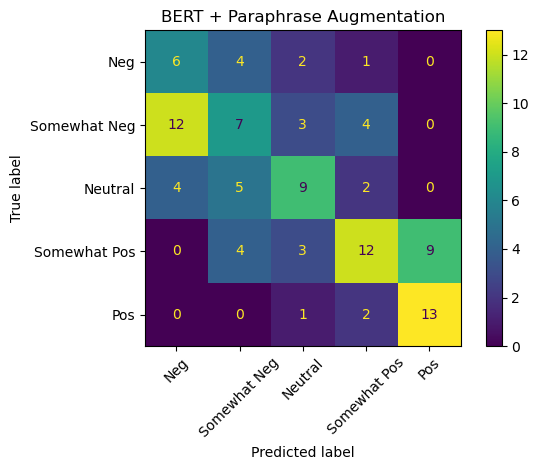

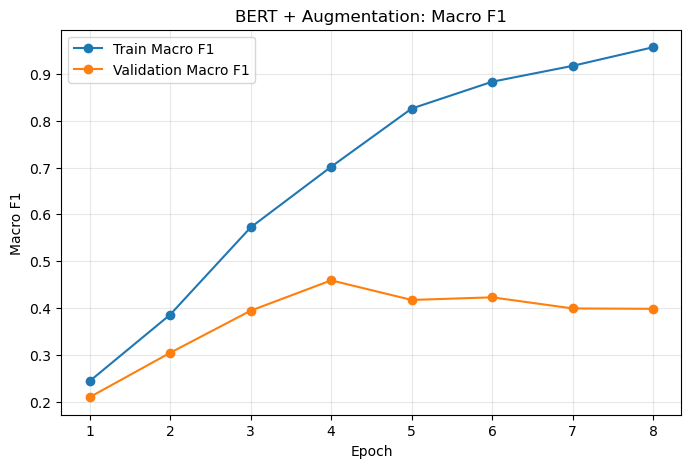


COMPARISON WITH ORIGINAL BERT
Original BERT Macro F1: 0.4505
Augmented BERT Macro F1: 0.4590
Difference: +0.0085

Augmentation IMPROVED validation Macro F1.


In [4]:
# ============================================================
# BERT TRAINING + EVALUATION ON AUGMENTED DATA — ONE CELL
#
# Train:
#   augmented_train_df
#
# Validation:
#   val_df  (untouched real data)
#
# Model:
#   bert-base-uncased
#
# Freeze:
#   embeddings + first 8 transformer layers
#
# Train:
#   last 4 transformer layers + classifier
#
# Selection metric:
#   Validation Macro F1
# ============================================================

import copy
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# SETTINGS
# ============================================================

MODEL_NAME = "google-bert/bert-base-uncased"

NUM_LABELS = 5

MAX_LENGTH = 64
BATCH_SIZE = 8

EPOCHS = 8

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

RANDOM_SEED = 42


# ============================================================
# RANDOM SEEDS
# ============================================================

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)


# ============================================================
# DEVICE
# ============================================================

if torch.cuda.is_available():

    device = torch.device("cuda")

elif torch.backends.mps.is_available():

    device = torch.device("mps")

else:

    device = torch.device("cpu")


print("Device:", device)


# ============================================================
# CHECK DATA
# ============================================================

print("\nTraining size:", len(augmented_train_df))
print("Validation size:", len(val_df))


print("\nTraining class distribution:")

print(
    augmented_train_df["Sentiment"]
    .value_counts()
    .sort_index()
)


print("\nValidation class distribution:")

print(
    val_df["Sentiment"]
    .value_counts()
    .sort_index()
)


# ============================================================
# TOKENIZER
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)


# ============================================================
# DATASET
# ============================================================

class SentimentDataset(Dataset):

    def __init__(
        self,
        dataframe,
        tokenizer,
        max_length
    ):

        self.texts = (
            dataframe["Phrase"]
            .astype(str)
            .tolist()
        )

        self.labels = (
            dataframe["Sentiment"]
            .astype(int)
            .tolist()
        )

        self.tokenizer = tokenizer

        self.max_length = max_length


    def __len__(self):

        return len(self.texts)


    def __getitem__(
        self,
        idx
    ):

        text = self.texts[idx]

        label = self.labels[idx]


        encoding = self.tokenizer(

            text,

            padding="max_length",

            truncation=True,

            max_length=self.max_length,

            return_tensors="pt"
        )


        return {

            "input_ids":
                encoding["input_ids"]
                .squeeze(0),

            "attention_mask":
                encoding["attention_mask"]
                .squeeze(0),

            "labels":
                torch.tensor(
                    label,
                    dtype=torch.long
                )
        }


# ============================================================
# CREATE DATASETS
# ============================================================

train_dataset = SentimentDataset(

    augmented_train_df,

    tokenizer,

    MAX_LENGTH
)


val_dataset = SentimentDataset(

    val_df,

    tokenizer,

    MAX_LENGTH
)


# ============================================================
# DATALOADERS
# ============================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=0
)


val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=0
)


# ============================================================
# LOAD BERT
#
# eager attention avoids the MPS
# scaled_dot_product_attention dropout issue
# ============================================================

model = AutoModelForSequenceClassification.from_pretrained(

    MODEL_NAME,

    num_labels=NUM_LABELS,

    attn_implementation="eager"
)


model = model.to(device)


# ============================================================
# FREEZE EMBEDDINGS
# ============================================================

for param in model.bert.embeddings.parameters():

    param.requires_grad = False


# ============================================================
# FREEZE FIRST 8 BERT LAYERS
#
# BERT-base has 12 layers:
#
# Frozen:
#   0-7
#
# Trainable:
#   8-11
# ============================================================

for layer in model.bert.encoder.layer[:8]:

    for param in layer.parameters():

        param.requires_grad = False


# ============================================================
# PARAMETER COUNTS
# ============================================================

total_params = sum(

    p.numel()

    for p in model.parameters()
)


trainable_params = sum(

    p.numel()

    for p in model.parameters()

    if p.requires_grad
)


print(
    f"\nTotal parameters: "
    f"{total_params:,}"
)


print(
    f"Trainable parameters: "
    f"{trainable_params:,}"
)


print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(

    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY
)


# ============================================================
# EVALUATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate_model(
    model,
    data_loader
):

    model.eval()

    total_loss = 0.0

    all_predictions = []

    all_labels = []


    for batch in data_loader:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )


        outputs = model(

            input_ids=input_ids,

            attention_mask=attention_mask,

            labels=labels
        )


        loss = outputs.loss

        logits = outputs.logits


        total_loss += (
            loss.item()
            *
            labels.size(0)
        )


        predictions = torch.argmax(

            logits,

            dim=1
        )


        all_predictions.extend(

            predictions
            .cpu()
            .numpy()
        )


        all_labels.extend(

            labels
            .cpu()
            .numpy()
        )


    avg_loss = (
        total_loss
        /
        len(data_loader.dataset)
    )


    accuracy = accuracy_score(

        all_labels,

        all_predictions
    )


    macro_f1 = f1_score(

        all_labels,

        all_predictions,

        average="macro",

        zero_division=0
    )


    return (

        avg_loss,

        accuracy,

        macro_f1,

        np.array(all_labels),

        np.array(all_predictions)
    )


# ============================================================
# TRAINING
# ============================================================

best_val_f1 = -1

best_epoch = 0

best_model_state = None


history = {

    "train_loss": [],

    "train_accuracy": [],

    "train_f1": [],

    "val_loss": [],

    "val_accuracy": [],

    "val_f1": []
}


print("\n" + "=" * 70)

print("TRAINING BERT ON AUGMENTED DATA")

print("=" * 70)


for epoch in range(
    1,
    EPOCHS + 1
):

    model.train()

    running_loss = 0.0

    train_predictions = []

    train_labels = []


    for batch in train_loader:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )


        optimizer.zero_grad()


        outputs = model(

            input_ids=input_ids,

            attention_mask=attention_mask,

            labels=labels
        )


        loss = outputs.loss

        logits = outputs.logits


        loss.backward()


        torch.nn.utils.clip_grad_norm_(

            model.parameters(),

            max_norm=1.0
        )


        optimizer.step()


        running_loss += (

            loss.item()

            *
            labels.size(0)
        )


        predictions = torch.argmax(

            logits,

            dim=1
        )


        train_predictions.extend(

            predictions
            .detach()
            .cpu()
            .numpy()
        )


        train_labels.extend(

            labels
            .detach()
            .cpu()
            .numpy()
        )


    # ========================================================
    # TRAIN METRICS DURING TRAINING
    # ========================================================

    train_loss = (

        running_loss
        /
        len(train_dataset)
    )


    train_accuracy = accuracy_score(

        train_labels,

        train_predictions
    )


    train_f1 = f1_score(

        train_labels,

        train_predictions,

        average="macro",

        zero_division=0
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    (
        val_loss,
        val_accuracy,
        val_f1,
        _,
        _
    ) = evaluate_model(

        model,

        val_loader
    )


    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_accuracy
    )

    history["train_f1"].append(
        train_f1
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_accuracy"].append(
        val_accuracy
    )

    history["val_f1"].append(
        val_f1
    )


    print(

        f"\nEpoch {epoch}/{EPOCHS}"

    )


    print(

        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Train Macro F1: {train_f1:.4f}"

    )


    print(

        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:   {val_accuracy:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"

    )


    # ========================================================
    # SAVE BEST MODEL BY VALIDATION MACRO F1
    # ========================================================

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        best_epoch = epoch

        best_model_state = copy.deepcopy(
            model.state_dict()
        )


        print(
            ">>> New best model saved."
        )


# ============================================================
# RESTORE BEST MODEL
# ============================================================

model.load_state_dict(
    best_model_state
)


print("\n" + "=" * 70)

print(
    f"RESTORED BEST EPOCH: {best_epoch}"
)

print(
    f"BEST VALIDATION MACRO F1: "
    f"{best_val_f1:.4f}"
)

print("=" * 70)


# ============================================================
# FINAL TRAIN EVALUATION
#
# This evaluates training data in model.eval() mode.
# Better for checking overfitting than the metrics recorded
# during training because dropout is disabled.
# ============================================================

(
    final_train_loss,
    final_train_accuracy,
    final_train_f1,
    final_train_labels,
    final_train_pred
) = evaluate_model(

    model,

    train_loader
)


# ============================================================
# FINAL VALIDATION EVALUATION
# ============================================================

(
    final_val_loss,
    final_val_accuracy,
    final_val_f1,
    final_val_labels,
    final_val_pred
) = evaluate_model(

    model,

    val_loader
)


# ============================================================
# FINAL RESULTS
# ============================================================

print("\n" + "=" * 70)

print("FINAL AUGMENTED BERT RESULTS")

print("=" * 70)


print(
    f"\nBest Epoch: {best_epoch}"
)


print("\nTRAIN:")

print(
    f"Loss:      {final_train_loss:.4f}"
)

print(
    f"Accuracy:  {final_train_accuracy:.4f}"
)

print(
    f"Macro F1:  {final_train_f1:.4f}"
)


print("\nVALIDATION:")

print(
    f"Loss:      {final_val_loss:.4f}"
)

print(
    f"Accuracy:  {final_val_accuracy:.4f}"
)

print(
    f"Macro F1:  {final_val_f1:.4f}"
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nValidation Classification Report:")

print(

    classification_report(

        final_val_labels,

        final_val_pred,

        labels=[0, 1, 2, 3, 4],

        target_names=[
            "Negative",
            "Somewhat Negative",
            "Neutral",
            "Somewhat Positive",
            "Positive"
        ],

        digits=3,

        zero_division=0
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

ConfusionMatrixDisplay.from_predictions(

    final_val_labels,

    final_val_pred,

    labels=[0, 1, 2, 3, 4],

    display_labels=[
        "Neg",
        "Somewhat Neg",
        "Neutral",
        "Somewhat Pos",
        "Pos"
    ]
)

plt.title(
    "BERT + Paraphrase Augmentation"
)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# ============================================================
# TRAINING CURVE — MACRO F1
# ============================================================

epochs_range = range(
    1,
    EPOCHS + 1
)


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history["train_f1"],
    marker="o",
    label="Train Macro F1"
)

plt.plot(
    epochs_range,
    history["val_f1"],
    marker="o",
    label="Validation Macro F1"
)

plt.xlabel("Epoch")

plt.ylabel("Macro F1")

plt.title(
    "BERT + Augmentation: Macro F1"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ============================================================
# COMPARE AGAINST YOUR PREVIOUS BEST
# ============================================================

PREVIOUS_BEST_F1 = 0.4505


print("\n" + "=" * 70)

print("COMPARISON WITH ORIGINAL BERT")

print("=" * 70)


print(
    f"Original BERT Macro F1: "
    f"{PREVIOUS_BEST_F1:.4f}"
)


print(
    f"Augmented BERT Macro F1: "
    f"{final_val_f1:.4f}"
)


difference = (
    final_val_f1
    -
    PREVIOUS_BEST_F1
)


print(
    f"Difference: "
    f"{difference:+.4f}"
)


if difference > 0:

    print(
        "\nAugmentation IMPROVED "
        "validation Macro F1."
    )

elif difference < 0:

    print(
        "\nAugmentation did NOT improve "
        "validation Macro F1."
    )

else:

    print(
        "\nPerformance is unchanged."
    )